# 🐱 Herding Quantum Cats
### Qiskit Fall Fest 2026 · University of Stuttgart · Hackathon challenge (beginner → intermediate)

**May 2016:** IBM put a 5-qubit quantum processor on the cloud, free for anyone with a browser.
**Ten years later**, anyone with a free account can run circuits on 156-qubit IBM Heron processors, today, from this notebook.

To celebrate, we revisit one of the very first things people did with those 5 cloud qubits: **entangle them into a "cat state".**

$$|\text{cat}_N\rangle = \frac{|00\ldots0\rangle + |11\ldots1\rangle}{\sqrt2}$$

Like Schrödinger's cat, the $N$ qubits are *all 0* ("alive") and *all 1* ("dead") **at the same time**. Physicists call it a [**GHZ state**](https://en.wikipedia.org/wiki/Greenberger%E2%80%93Horne%E2%80%93Zeilinger_state), after Daniel Greenberger, Michael Horne and Anton Zeilinger. It is the most fragile state there is: a single error on *any* of the $N$ qubits spoils it. That makes it the perfect benchmark for a quantum computer. In 2025, IBM entangled **120 qubits** this way ([“Big cats”, arXiv:2510.09520](https://arxiv.org/abs/2510.09520)) with a fidelity of 0.56 (fidelity = how close the state is to the perfect cat, between 0 and 1; Mission 0 explains it).

**Your job: herd qubits into the cleanest and biggest cat you can.** On the way you will learn what the transpiler actually does, why *where* a circuit runs on a chip matters, and how error suppression and error mitigation squeeze good results out of noisy hardware.

## 🏆 What you are aiming for
There are two leaderboards:
* 🧼 **Cleanest Cat:** a cat of exactly **12 qubits** whose fidelity is as close to 1 as possible, on the simulator *and* on the real ibm_kingston. You are compared with a deliberately naive cat prepared by the organizers (the *baseline*, Mission 2).
* 🦁 **Biggest Cat:** the largest cat you can *prove* is genuinely entangled (Missions 0 and 8 explain what "prove" means here).

Points also come from finishing Missions 0–5, from four short answers at the end, and from a small table of evidence you fill in along the way. The exact formulas need a few ideas you'll meet first, so the **full scoring table is just before Mission 6**.

### Ground rules
* **Develop on the simulator.** QPU time is precious: **10 minutes per person per 28 days** on the free Open Plan, and the queue can be long. Use the real chip only in Mission 7 (and Mission 8 if you like).
* ⏰ **Submit your final hardware job by 18:45.** Results that arrive late can still be posted until 21:00.
* 📦 **By 20:00**, **one person per team** posts three files in the Discord channel the organizers name: this notebook (run, *with outputs*, renamed `team_<name>.ipynb`), your `submission_<team>.json` (made in the last cell) and your pitch deck `pitch_<team>.pdf` or `.pptx` (5 minutes, see `PITCH.md`).
* 🎤 The deck is not scored, but **the winning team presents it at the award ceremony**.
* Ask the supervisors. That's what they are here for!

## 🧭 Map of the afternoon

| Mission | Topic | Level |
|---|---|---|
| 0 | Your first cat (ideal world) | 🟢 guided |
| 1 | Then vs. now: a 2017 chip vs. a 2026 chip | 🟢 guided |
| 2 | **Layout**: where should the cat live? | 🟢→🟡 |
| 3 | **Depth**: grow the cat faster | 🟡 |
| 4 | Error **suppression**: echoes and twirls | 🟢 guided |
| 5 | Error **mitigation**: readout correction and zero-noise extrapolation | 🟡 |
| 6 | Your **Cleanest Cat** (N = 12) | 🟡 open |
| 7 | 🚀 **The real thing**: ibm_kingston | 🟡 |
| 8 | 🦁 **The Biggest Cat** | 🟠 open |

Go at your own pace. The only fixed times are the two deadlines above: the hardware job by **18:45** and the files by **20:00**. Because of the hardware queue, it helps to reach Mission 7 by about 17:30.

Levels: 🟢 = beginner (guided step by step), 🟡 = intermediate, 🟠 = advanced and open-ended.

Symbols: ✍️ = your turn (code to write), ✅ = self-check, 💡 = hint, ⭐ = harder and optional (skip it if you're short on time), 🔍 = optional background in a box you can click open. You can do every mission without opening the 🔍 boxes.

## Setup
You need `qiskit`, `qiskit-ibm-runtime`, `qiskit-aer` and the file **`herding_cats.py`** (our toolkit) in the same folder as this notebook.

💡 Install the packages in a **virtual environment**, so they don't clash with other Python projects on your laptop. In a terminal:
```bash
python -m venv fallfest            # once: creates the folder "fallfest"
source fallfest/bin/activate       # macOS/Linux   (Windows: fallfest\Scripts\activate)
pip install "qiskit[visualization]==2.6.1" "qiskit-ibm-runtime==0.51.0" "qiskit-aer==0.18.0" jupyterlab
jupyter lab                        # opens this notebook in your browser
```
(With conda: `conda create -n fallfest python=3.12`, then `conda activate fallfest` and the same `pip install`.)

In [1]:
# If something is missing, install it into the environment this notebook runs in:
# %pip install "qiskit[visualization]==2.6.1" "qiskit-ibm-runtime==0.51.0" "qiskit-aer==0.18.0"
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

import numpy as np
import matplotlib.pyplot as plt
import qiskit, qiskit_aer, qiskit_ibm_runtime
from qiskit import QuantumCircuit
from qiskit.primitives import StatevectorSampler
from qiskit.transpiler import generate_preset_pass_manager
from qiskit.visualization import timeline_drawer

import herding_cats as hc   # the hackathon toolkit

print(f"qiskit {qiskit.__version__} | qiskit-ibm-runtime {qiskit_ibm_runtime.__version__} | "
      f"qiskit-aer {qiskit_aer.__version__} | herding_cats {hc.__version__}")

import os, json, math
from pathlib import Path
from collections import deque
from dataclasses import asdict
from IPython.display import display, HTML, Markdown
import qats
from qats import quality

# Local Aer workaround; same full noise model and scoring rules.
hc.CatSimulator = qats.StableCatSimulator


qiskit 2.6.1 | qiskit-ibm-runtime 0.51.0 | qiskit-aer 0.18.0 | herding_cats 1.0.0


## 🧰 The toolkit at a glance
`herding_cats.py` (imported as `hc`) hides the plumbing so you can focus on the physics. You don't need to read its code. Every function is explained where it first appears, so you can skip the reference table below and come back to it whenever you meet an unfamiliar `hc.` name. `help(hc.<name>)` prints a function's documentation.

<details>
<summary>📖 Reference: all toolkit functions used in this notebook (click to open)</summary>

| Function | What it does |
|---|---|
| `hc.fake_kingston()`, `hc.fake_yorktown()` | Offline copies of two real IBM chips: their qubit map and calibration data (error rates, $T_1$, $T_2$). No account needed. |
| `hc.CatSimulator(backend)` | A noisy simulator of that chip ("the Fall Fest simulator"). `.run(circuits, shots)` returns measurement counts. |
| `hc.cat_fidelity(counts_z, counts_x)` | Turns Z- and X-basis counts into $P$, $X$ and the fidelity $F$, with error bars (Mission 0). |
| `hc.measure_cat_quality(cat, simulator, recipe, total_shots)` | Does the whole measurement for you: adds Z- and X-basis measurements to your cat, runs them, returns $F \pm \sigma_F$. |
| `hc.Recipe(...)` | *How* to measure: which error suppression / mitigation tricks to switch on (Missions 4–5). |
| `hc.baseline_cat(backend)` | The organizers' reference cat (Mission 2). |
| `hc.cat_report(cat, backend)` | Quick quality check *without* simulating: gate counts, depth, idle time, estimated success probability. |
| `hc.show_chip(backend, cat)` | Draws the chip and where your cat sits on it. |
| `hc.qubit_quality(backend)` | Per-qubit (readout error, $T_1$, $T_2$) and per-coupler (CZ error) calibration numbers. |
| `hc.cat_qubits(cat)` | The physical qubits your transpiled cat uses, in cat order. |
| `hc.verify_cat(circuit)` | Exact, noiseless check that a circuit really prepares a cat. |
| `hc.scorecard(...)` | Estimates your Cleanest Cat points (Mission 6). |
| `hc.FinalJob`, `hc.HardwareRunner`, `hc.connect_to_hardware` | Running on the real chip (Mission 7). |
| `hc.save_submission(...)` | Writes your submission file (last cell). |
</details>

---
# Mission 0 · Your first cat (in an ideal world) 🟢
🎯 *Build a cat, measure it, and learn the one number that tells a real cat from a fake one.*

The recipe: put one qubit into superposition with a Hadamard, then copy its value along a chain with CNOTs:
$\;|000\rangle \xrightarrow{H} \tfrac{1}{\sqrt2}(|000\rangle+|100\rangle) \xrightarrow{\text{CNOTs}} \tfrac{1}{\sqrt2}(|000\rangle+|111\rangle)$.

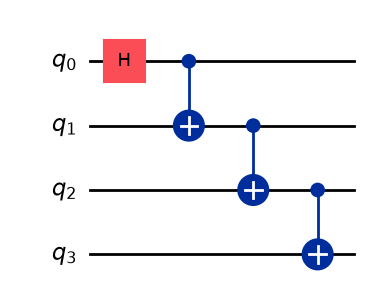

In [2]:
def make_cat(n):
    # Return an n-qubit circuit that prepares (|00...0> + |11...1>)/√2.
    qc = QuantumCircuit(n)
    # ✍️ YOUR CODE HERE: Hadamard on qubit 0, then CNOTs 0→1, 1→2, ...
    qc.h(0)
    for i in range(n - 1):
        qc.cx(i, i + 1)
    return qc

make_cat(4).draw("mpl")

### How do we know it's a cat?
A real quantum computer never gives us the state itself, only measurement outcomes ("shots"): every shot returns one bitstring such as `011`. We repeat the circuit thousands of times and count how often each bitstring appears.

**Measurement A, the Z basis (the usual one).** For a perfect cat, every shot gives either `000` or `111`, each about half of the time. That shows the qubits *agree*, but it doesn't show the superposition: a **classical coin** that secretly sets all qubits to 0 *or* all to 1 (we'll build one below) gives exactly the same histogram.

**Measurement B, the X basis.** We apply a Hadamard gate to every qubit just before measuring. For the cat, the two halves $|000\rangle$ and $|111\rangle$ then *interfere*: outcomes with an odd number of 1s cancel out, and only outcomes with an **even** number of 1s survive (`000`, `011`, `101`, `110`). This interference happens only if both halves are present *at the same time*, so it is the fingerprint of the superposition.

From the two measurements we compute two numbers:
* $P$ = fraction of Z-basis shots in which **all qubits agree** (all 0 or all 1). Perfect cat: $P = 1$. *Is the cat alive OR dead, and nothing in between?*
* $X$ = the **parity**: for every X-basis shot, write $+1$ if it has an even number of 1s and $-1$ if odd, then average over all shots. (Physicists write this as the expectation value $\langle X\otimes X \otimes\cdots\otimes X\rangle$.) Perfect cat: $X = +1$. No superposition at all: $X \approx 0$. *Are alive and dead in superposition?*

### Fidelity
The **fidelity** $F$ of a prepared state is its overlap with the perfect cat: the probability that it would pass the test "are you the perfect cat?". $F = 1$ means perfect; $F = 0$ means nothing in common. We can't measure $F$ directly with just two measurement settings, but $P$ and $X$ give a guaranteed lower bound:
$$F \;\ge\; P + \frac{X - 1}{2}$$
In words: start from $P$ (how often the qubits agree), and subtract a penalty when the parity $X$ falls short of 1 (missing superposition). The true fidelity can only be *higher* than this number, so we're never fooling ourselves. From now on, "$F$" means this lower bound.

In [3]:
def measured(cat, basis):
    # Copy of `cat` with measurements in the Z basis (as is) or in the X basis (Hadamards first).
    qc = cat.copy()
    if basis == "X":
        qc.h(range(qc.num_qubits))
    qc.measure_all()
    return qc

ideal = StatevectorSampler(seed=2026)          # a perfect, noiseless quantum computer
cat3 = make_cat(3)
result = ideal.run([measured(cat3, "Z"), measured(cat3, "X")], shots=2000).result()
counts_z = result[0].data.meas.get_counts()
counts_x = result[1].data.meas.get_counts()
print("Z basis:", counts_z)
print("X basis:", counts_x)

Z basis: {'000': 983, '111': 1017}
X basis: {'000': 484, '101': 505, '011': 499, '110': 512}


In [4]:
def prob_all_equal(counts):
    return sum(count for bits, count in counts.items()
               if len(set(bits.replace(" ", ""))) == 1) / sum(counts.values())

def parity(counts):
    return sum((-1)**bits.count("1") * count for bits, count in counts.items()) / sum(counts.values())

P, X = prob_all_equal(counts_z), parity(counts_x)
print(f"P = {P:.3f}   X = {X:.3f}   ->   F ≥ P + (X-1)/2 = {P + (X-1)/2:.3f}")


P = 1.000   X = 1.000   ->   F ≥ P + (X-1)/2 = 1.000


In [5]:
# ✅ Check: your functions must agree with the toolkit
reference = hc.cat_fidelity(counts_z, counts_x)
assert abs(P - reference.P) < 1e-9 and abs(X - reference.X) < 1e-9, "Not quite: compare with hc.cat_fidelity"
print("✅", reference)

✅ CatResult(N=3: F = 1.000 ± 0.000 [certified ✓] | P = 1.000 ± 0.000, X = 1.000 ± 0.000)


`hc.cat_fidelity(counts_z, counts_x)` computes the same $P$, $X$ and $F$ from the two sets of counts, and adds error bars (the `±`; explained below).

### A fake cat
Now let's build the classical coin. Imagine someone flips a coin before every shot and prepares either $|000\rangle$ (heads) or $|111\rangle$ (tails), with plain X gates and no superposition anywhere. We simulate it by running the two circuits separately and merging their counts, so half of the shots come from each.

* **Z basis:** half `000`, half `111`, the same as the real cat, so $P = 1$.
* **X basis:** a Hadamard on a qubit that is *definitely* 0 or *definitely* 1 gives a 50/50 random bit. With no second half to interfere with, nothing cancels: all 8 bitstrings appear equally often, half of them with even and half with odd parity, so $X \approx 0$.
* Fidelity bound: $F = 1 + (0 - 1)/2 = 0.5$.

In [6]:
alive = QuantumCircuit(3)                      # all qubits 0
dead = QuantumCircuit(3); dead.x(range(3))     # all qubits 1
coin_results = ideal.run([measured(alive, "Z"), measured(dead, "Z"),
                          measured(alive, "X"), measured(dead, "X")], shots=1000).result()

def merge(*many_counts):
    # Add up several counts dictionaries (as if all shots came from one experiment).
    total = {}
    for counts in many_counts:
        for bits, n_shots in counts.items():
            total[bits] = total.get(bits, 0) + n_shots
    return total

fake_z = merge(coin_results[0].data.meas.get_counts(), coin_results[1].data.meas.get_counts())
fake_x = merge(coin_results[2].data.meas.get_counts(), coin_results[3].data.meas.get_counts())
print("fake cat, Z basis:", fake_z)
print("fake cat, X basis:", fake_x)
print("fake cat:", hc.cat_fidelity(fake_z, fake_x))

fake cat, Z basis: {'000': 1000, '111': 1000}
fake cat, X basis: {'001': 228, '101': 254, '011': 242, '010': 240, '110': 254, '111': 284, '100': 280, '000': 218}
fake cat: CatResult(N=3: F = 0.484 ± 0.011 [not certified] | P = 1.000 ± 0.000, X = -0.032 ± 0.022)


💭 **Think about it:** the fake cat scores $F = 0.5$, up to *shot noise* (the random scatter from using a finite number of shots, see below). That's no accident: it is proven that any state in which some group of qubits is *not* entangled with the rest scores at most 0.5. So
**$F > 0.5$ proves genuine $N$-qubit entanglement.**

### Error bars: how sure are we?
$P$ and $X$ are estimated from a finite number of shots, so they come with statistical uncertainty, just like estimating the bias of a coin from 1000 flips. The `±` numbers are **standard deviations** ($\sigma$), estimated from the data:
* $P$ is a fraction of shots (a yes/no count), so $\sigma_P = \sqrt{P(1-P)/n_Z}$, the standard error of a binomial proportion with $n_Z$ Z-basis shots.
* $X$ is the average of $n_X$ values that are each $\pm1$, so $\sigma_X = \sqrt{(1 - X^2)/n_X}$, the standard error of a mean.
* $P$ and $X$ come from independent measurements, so the uncertainties add in quadrature (standard error propagation): $\sigma_F = \sqrt{\sigma_P^2 + (\sigma_X/2)^2}$.

The error bars shrink like $1/\sqrt{\text{shots}}$: four times the shots, half the error bar. (Later, error mitigation makes these formulas more complicated. The toolkit then uses the **bootstrap**: it resamples the measured shots 200 times, recomputes $F$ each time, and takes the spread of the results as $\sigma_F$.)

A measured $F$ just above 0.5 could be a lucky fluctuation. So we call a cat **certified ✓** only if it is above 0.5 by at least two standard deviations: $F - 2\sigma_F > 0.5$. (For a normally distributed estimate, a fluctuation that large happens by chance in only about 2% of cases.)

<details>
<summary>🔍 <b>Comparing two results: did a change really help?</b> (click to open)</summary>

Two independent results $F_1 \pm \sigma_1$ and $F_2 \pm \sigma_2$ differ significantly only if $|F_1 - F_2| > 2\sqrt{\sigma_1^2 + \sigma_2^2}$. For example, $0.726 \pm 0.007$ vs. $0.741 \pm 0.007$ differ by $0.015$, but $2\sqrt{0.007^2 + 0.007^2} \approx 0.020$: not significant. When you compare many recipes, a few "2σ differences" appear by pure chance (about 1 in 20 comparisons), so re-run with a different simulator seed before you believe a small gain.
</details>

---
# Mission 1 · Then vs. now: ten years of cloud cats 🟢
🎯 *Run the same 5-qubit cat on a 2017 chip and on a 2026 chip.*

IBM measures the error rates of every qubit and coupler of its chips several times a day (a *calibration*). Qiskit ships **calibration snapshots**, frozen copies of one such measurement, as "fake backends" that work offline. The toolkit gives you two:
* `hc.fake_yorktown()`: **ibmqx2 "Yorktown"**, one of the first public 5-qubit processors on the IBM Quantum Experience (online 2017–2021);
* `hc.fake_kingston()`: **ibm_kingston**, a 156-qubit **IBM Heron r2**, available to every free account today. Its snapshot was taken on **15 April 2026**. You'll run on the real chip in Mission 7.

We simulate both with `hc.CatSimulator(backend)`, a noisy simulator that uses the chip's own calibration data: gate errors, readout errors, $T_1$ (how long a qubit stays in $|1\rangle$ before relaxing to $|0\rangle$), $T_2$ (how long a superposition keeps its phase), and slow frequency noise while qubits sit idle.

`hc.qubit_quality(backend)` returns two dictionaries. In the first, `qubit_info[q]` holds the readout error, $T_1$ and $T_2$ of qubit `q`. In the second, `cz_errors[(q1, q2)]` holds the error rate of a CZ gate between two neighbouring qubits `q1 < q2`. The cell prints the median of each over the whole chip.

In [7]:
yorktown = hc.fake_yorktown()
kingston = hc.fake_kingston()

for chip in (yorktown, kingston):
    qubit_info, cz_errors = hc.qubit_quality(chip)
    print(f"{chip.name:15s} {chip.num_qubits:4d} qubits | "
          f"2-qubit gate error {100 * np.median(list(cz_errors.values())):.2f}% | "
          f"readout error {100 * np.nanmedian([info['readout'] for info in qubit_info.values()]):.2f}% | "
          f"T2 {1e6 * np.median([info['t2'] for info in qubit_info.values() if info['t2']]):.0f} µs   (medians)")

fake_yorktown      5 qubits | 2-qubit gate error 2.14% | readout error 6.33% | T2 25 µs   (medians)


fake_kingston    156 qubits | 2-qubit gate error 0.18% | readout error 0.95% | T2 144 µs   (medians)


A quantum chip only understands its own **native gates** on its own **physical qubits**. The **transpiler** rewrites your circuit into such an *ISA circuit* ("instruction set architecture"). In Qiskit 2.x, you make a *pass manager* for a backend and run your circuit through it.

Then `hc.measure_cat_quality(isa_circuit, simulator, total_shots=4000)` does everything from Mission 0 for you: it adds the Z-basis and X-basis measurements, runs both on the simulator (half of the shots each), and returns $F$, $P$ and $X$ with error bars.

In [8]:
then_now = {}
for chip in (yorktown, kingston):
    pass_manager = generate_preset_pass_manager(optimization_level=1, backend=chip, seed_transpiler=1)
    isa_cat = pass_manager.run(make_cat(5))   # ✍️ YOUR CODE HERE: use the pass manager to transpile make_cat(5)
    then_now[chip.name] = hc.measure_cat_quality(isa_cat, hc.CatSimulator(chip), total_shots=4000)
    print(f"{chip.name:15s}", then_now[chip.name])


fake_yorktown   CatResult(N=5: F = 0.088 ± 0.017 [not certified] | P = 0.502 ± 0.012, X = 0.171 ± 0.022)


fake_kingston   CatResult(N=5: F = 0.587 ± 0.013 [certified ✓] | P = 0.787 ± 0.009, X = 0.598 ± 0.019)


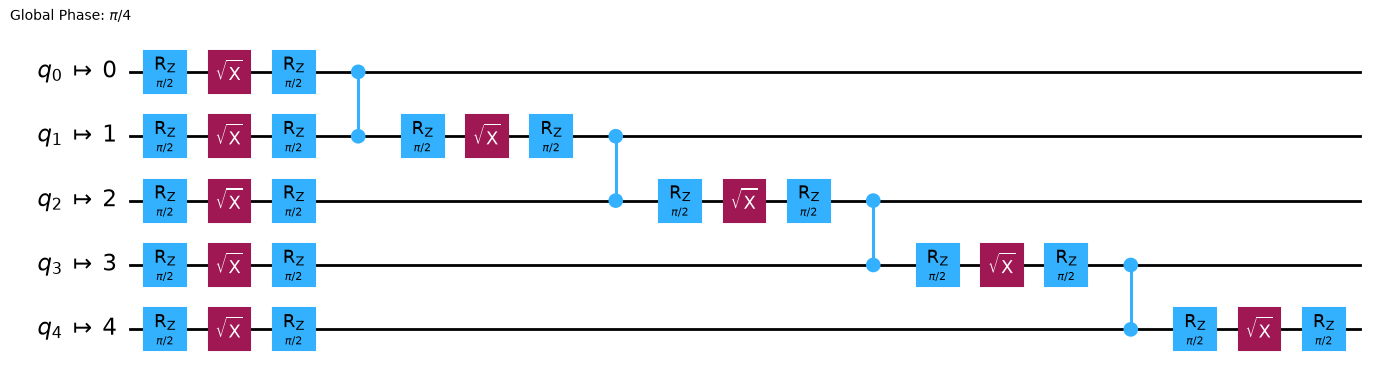

In [9]:
# The 2026 version as the chip sees it: native gates (rz, sx, x, cz) on physical qubits
isa_cat.draw("mpl", idle_wires=False, fold=-1)

💭 Look at the drawing: your 4 CNOTs became CZ gates sandwiched between single-qubit rotations, and your qubits 0–4 now have physical names. *How much better is the 2026 cat than the 2017 cat, and which of the chip properties printed above (the median 2-qubit gate error, readout error and $T_2$ of each chip) explains most of it?* (Not graded; just talk about it in your team.)

🕵️ **A puzzle to keep in mind:** a 5-qubit cat on a 2026 chip whose median errors are below 1% should do better than $F \approx 0.6$. Something is off. Mission 2 finds out what.

---
# Mission 2 · Where should the cat live? (layout) 🟢→🟡
🎯 *Find out why the default cat fails, and choose better qubits.*

From now on we work with **12-qubit cats** (the size of the 🧼 Cleanest Cat leaderboard) on `fake_kingston`.

The organizers' **baseline cat** is what you get with no effort at all: the textbook chain circuit from Mission 0 with 12 qubits, transpiled with Qiskit's default settings (`optimization_level=1`) and measured without any error suppression or mitigation. `hc.baseline_cat(backend)` builds exactly this circuit. All Cleanest Cat scores are measured *relative to* this baseline. Let's see how well it does.

`hc.cat_report(cat, backend)` summarizes a transpiled cat without simulating it: the number of two-qubit gates (`two_qubit_gates`), how many of them are extra gates from SWAPs (`swap_overhead`), the two-qubit depth (how many CZ layers run one after another), the circuit duration, the total time qubits wait after joining the cat (`idle_after_entangling_us`), an estimated success probability (`ESP`, explained below) and the physical qubits used.

In [10]:
backend = hc.fake_kingston()
sim = hc.CatSimulator(backend)          # the Fall Fest simulator (fixed seed, so results are reproducible)
N = hc.CLEAN_CAT_SIZE                   # = 12

baseline = hc.baseline_cat(backend, N)
baseline_result = hc.measure_cat_quality(baseline, sim, total_shots=8000)
print(baseline_result)
hc.cat_report(baseline, backend)

CatResult(N=12: F = 0.442 ± 0.010 [not certified] | P = 0.702 ± 0.007, X = 0.481 ± 0.015)


{'n': 12,
 'two_qubit_gates': 11,
 'swap_overhead': 0,
 'two_qubit_depth': 11,
 'duration_us': 1.144,
 'idle_after_entangling_us': 5.924,
 'ESP': 0.663589176841114,
 'qubits': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]}

😿 The default cat is **not even certified**: the transpiler made a valid circuit, but not a good one. Let's look at *where* it put the cat. In the chip map below, qubits are coloured by their **readout error** and the numbers are positions in the cat.

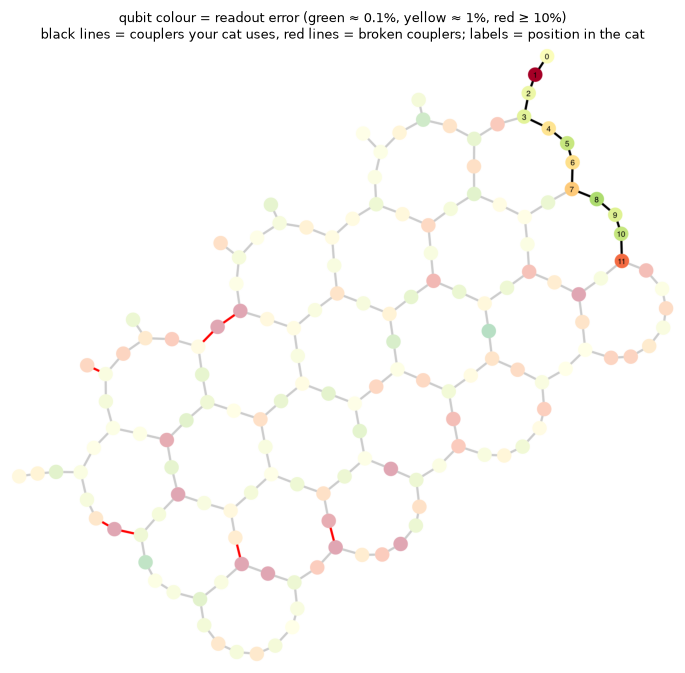

In [11]:
hc.show_chip(backend, baseline);

In [12]:
qubit_info, cz_errors = hc.qubit_quality(backend)
for position, physical in enumerate(hc.cat_qubits(baseline)):     # cat_qubits: physical qubits, in cat order
    print(f"cat qubit {position:2d} -> physical qubit {physical:3d}: "
          f"readout error {100 * qubit_info[physical]['readout']:5.2f}%   T2 = {1e6 * qubit_info[physical]['t2']:4.0f} µs")

cat qubit  0 -> physical qubit   0: readout error  0.95%   T2 =  354 µs
cat qubit  1 -> physical qubit   1: readout error 16.82%   T2 =  329 µs
cat qubit  2 -> physical qubit   2: readout error  0.79%   T2 =  110 µs
cat qubit  3 -> physical qubit   3: readout error  0.72%   T2 =  400 µs
cat qubit  4 -> physical qubit   4: readout error  1.49%   T2 =   79 µs
cat qubit  5 -> physical qubit   5: readout error  0.54%   T2 =   63 µs
cat qubit  6 -> physical qubit   6: readout error  1.59%   T2 =  138 µs
cat qubit  7 -> physical qubit   7: readout error  1.94%   T2 =   98 µs
cat qubit  8 -> physical qubit   8: readout error  0.43%   T2 =   86 µs
cat qubit  9 -> physical qubit   9: readout error  0.68%   T2 =   41 µs
cat qubit 10 -> physical qubit  10: readout error  0.52%   T2 =   26 µs
cat qubit 11 -> physical qubit  11: readout error  4.06%   T2 =  105 µs


✍️ **Write down for your team:** which physical qubit(s) ruin the baseline? (You'll need this for answer Q1.)

### What the transpiler does
| Stage | Job | Why it matters for cats |
|---|---|---|
| **layout** | assign each circuit qubit to a physical qubit | good vs. bad qubits! |
| **routing** | insert SWAPs when two qubits that must interact are not neighbours | every SWAP = 3 extra CZs |
| **translation** | rewrite gates into native gates (`cz`, `rz`, `sx`, `x`) | |
| **optimization** | merge and cancel gates | fewer gates, less noise |
| **scheduling** | decide *when* each gate runs; idle times appear | idle qubits decohere |

`optimization_level` (0–3) controls how hard each stage tries. Some stages make random choices; `seed_transpiler` fixes them so that you get the same result every time you run the cell.

The **ESP** ("estimated success probability") in `cat_report` is a quick, simulation-free quality estimate: the probability that *nothing at all* goes wrong, if every error happened independently:
$$\text{ESP} = \prod_\text{gates}(1-\text{gate error})\;\prod_\text{qubits}(1-\text{readout error})\;\prod_\text{qubits} e^{-t_\text{idle}/T_2}$$
It ignores many details, so use it to *compare* candidate circuits, not to predict $F$.

Let's compare the four optimization levels (`hc.ghz_linear(N)` is the same chain circuit as your `make_cat(N)`):

In [13]:
print("level | CZs  SWAP-overhead   ESP  | physical qubits")
for level in range(4):
    pass_manager = generate_preset_pass_manager(optimization_level=level, backend=backend, seed_transpiler=1)
    report = hc.cat_report(pass_manager.run(hc.ghz_linear(N)), backend)
    print(f"  {level}   | {report['two_qubit_gates']:3d}      {report['swap_overhead']:3d}       "
          f"{report['ESP']:.3f} | {report['qubits']}")

level | CZs  SWAP-overhead   ESP  | physical qubits
  0   |  11        0       0.664 | [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
  1   |  11        0       0.664 | [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
  2   |  11        0       0.775 | [95, 94, 93, 79, 73, 74, 75, 59, 55, 54, 53, 52]


  3   |  11        0       0.758 | [52, 53, 54, 55, 59, 75, 74, 73, 79, 93, 94, 95]


💭 Levels 0 and 1 keep the *trivial* layout (circuit qubit $i$ → physical qubit $i$), because qubits 0–11 already form a chain on this chip. Levels 2 and 3 search for a layout that matches the circuit *and* has low error rates. (Try other values of `seed_transpiler`: for this small chain cat the result doesn't change, because the layout search here is not random. Seeds matter for bigger or more irregular circuits, where the transpiler tries random starting points.)

<details>
<summary>🔍 <b>Why is level 3 slightly worse than level 2 here?</b> (click to open)</summary>

Look at the qubit lists: both levels picked the *same 12 qubits*, just in opposite order. Level 2 starts the chain at qubit 95, level 3 at qubit 52. Gate and readout errors are identical either way. But the first qubits of a chain wait longest after joining the cat (Mission 3), and $T_2$ is very different at the two ends: about 520 µs at qubit 95 and 60 µs at qubit 52. Our ESP includes this waiting penalty; the transpiler's layout scoring only looks at gate and readout errors, so for it both directions are equally good. Lesson: a higher optimization level optimizes *the transpiler's* idea of quality, which isn't necessarily yours.
</details>

### ✍️ 2a · Choose the qubits yourself
Your cat is a **chain**: qubit $i$ talks to qubit $i+1$. Pick 12 physical qubits that form a connected chain on the chip, avoiding red (bad) qubits and red (broken) couplers. Then pass them to the transpiler as `initial_layout`.

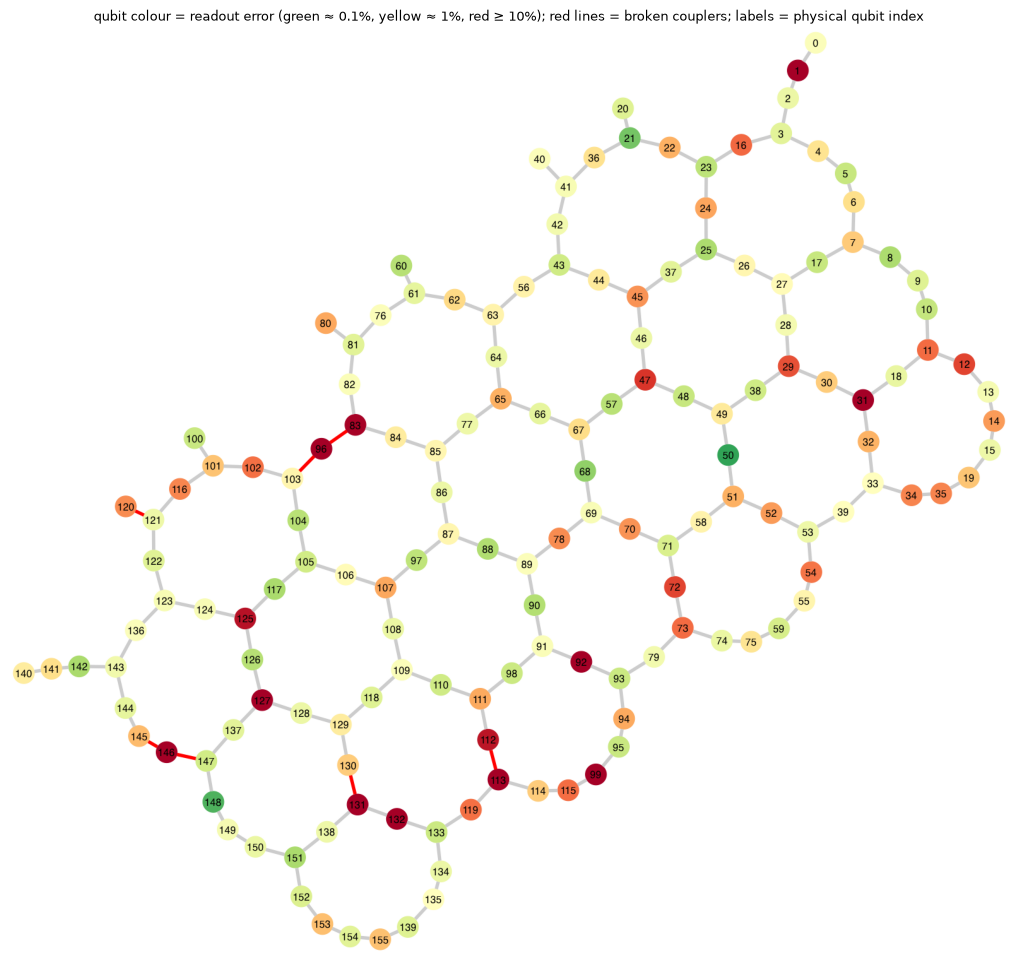

In [14]:
hc.show_chip(backend, figsize=(13, 12));   # all qubits labelled with their physical index

In [15]:
def is_line(backend, qubits):
    graph = backend.coupling_map.graph
    return len(set(qubits)) == len(qubits) and all(
        graph.has_edge(a, b) or graph.has_edge(b, a) for a, b in zip(qubits[:-1], qubits[1:]))

# An initial connected path; the exhaustive calibration search improves it next.
my_line = hc.cat_qubits(generate_preset_pass_manager(optimization_level=2,
    backend=backend, seed_transpiler=1).run(make_cat(N)))
print("valid chain:", len(my_line) == N and is_line(backend, my_line))


valid chain: True


How good is your choice? Transpile the chain cat onto your qubits (`initial_layout=my_line` tells the transpiler where to put circuit qubit 0, 1, 2, …) and compare its report with the baseline's. Try a few different chains: a higher ESP is better.

baseline   ESP = 0.664 | SWAP overhead 0 | qubits [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
your chain ESP = 0.775 | SWAP overhead 0 | qubits [95, 94, 93, 79, 73, 74, 75, 59, 55, 54, 53, 52]


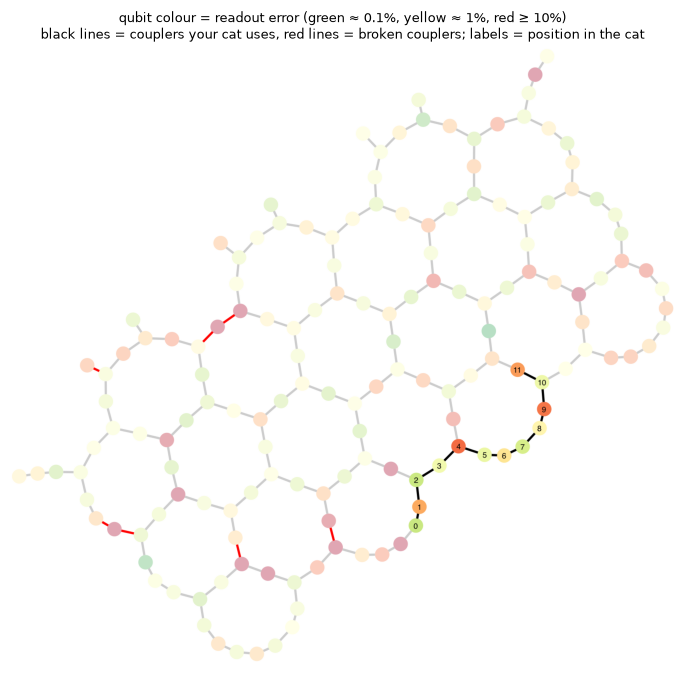

In [16]:
if len(my_line) == N and is_line(backend, my_line):
    hand_cat = generate_preset_pass_manager(optimization_level=3, backend=backend, initial_layout=my_line,
                                            seed_transpiler=1).run(hc.ghz_linear(N))
    for name, cat in [("baseline", baseline), ("your chain", hand_cat)]:
        report = hc.cat_report(cat, backend)
        print(f"{name:10s} ESP = {report['ESP']:.3f} | SWAP overhead {report['swap_overhead']} | qubits {report['qubits']}")
    hc.show_chip(backend, hand_cat);
else:
    print("my_line is not a valid 12-qubit chain yet")

### ⭐ 2b · Let the computer search
Picking by hand is fun, but a computer can try *every* chain and keep the best one ("brute force").

**How many chains are there?** Start on any of the 156 qubits. On the heavy-hex lattice every qubit has at most 3 neighbours, and you can't go back to the one you came from, so each further step offers at most 2 choices: at most $156 \cdot 3 \cdot 2^{10} \approx 480{,}000$ walks of 12 qubits. Most qubits have only 2 neighbours, though, and many walks run into themselves, so the real number is much smaller. Counting them with the search below gives about **6,000** on `fake_kingston` (each chain counted once from each end): 1,900 for $N = 8$, 5,900 for $N = 12$ and 15,800 for $N = 16$. Each extra qubit multiplies the count by about 1.3 (from $(15{,}800/1{,}900)^{1/8} \approx 1.3$), so it grows exponentially, but slowly. Fine for 12 qubits; for 50-qubit cats you'll need something smarter (Mission 8).

**How do we score a chain?** If every element works independently, the chance that the whole chain works is a *product* of success probabilities: $\prod_\text{qubits}(1-p_\text{readout}) \prod_\text{couplers}(1-p_\text{CZ})$. Taking $-\log$ turns the product into a *sum* of costs, $\sum -\log(1-p)$, where every cost is positive and lower is better. Sums are easier to build up step by step, and because costs only grow as a chain gets longer, we can **stop exploring** a partial chain as soon as it is already worse than the best complete chain found so far (*pruning*). That makes the search take about a second.

<details>
<summary>🔍 <b>Why no T₂ term, unlike ESP?</b> (click to open)</summary>

For a 12-qubit chain the waiting penalty is small (about 2 µs of waiting against $T_2 \approx$ 100–500 µs, a factor $e^{-0.01}$ per qubit), and it depends on *how* the cat will be grown on the chain (from one end, or from the middle as in Mission 3), which isn't decided yet when we search. Readout and CZ errors dominate. Adding a $T_2$ cost is a good ⭐ improvement for Mission 6, and it becomes important for big cats (Mission 8).
</details>

**Depth-first search (DFS)** builds chains one qubit at a time: extend the current chain by a neighbour, go as deep as possible, and when you reach 12 qubits (or a dead end), step back and try the next neighbour.

<details>
<summary>💡 Hint: DFS in pseudocode (click to open)</summary>

```
function dfs(path, cost):
    if cost >= best cost so far:        # pruning: can't win any more
        return
    if path has n qubits:
        remember path and cost as the new best
        return
    for each neighbour of the last qubit in path:
        if neighbour is not already in path:
            add neighbour to path
            dfs(path, cost + coupler_cost(last, neighbour) + qubit_cost(neighbour))
            remove neighbour from path   # step back ("backtrack")

for every qubit q on the chip:
    dfs([q], qubit_cost(q))
```
</details>

In [17]:
def line_candidates(backend, n, limit=24):
    qinfo, errors = quality(backend)
    neighbours = {q: set() for q in range(backend.num_qubits)}
    for a, b in backend.coupling_map.get_edges():
        if tuple(sorted((a, b))) in errors:
            neighbours[a].add(b)
            neighbours[b].add(a)
    qcost = {q: -math.log(max(1e-9, 1 - v["readout"]))
             if np.isfinite(v["readout"]) else float("inf") for q, v in qinfo.items()}
    ecost = {e: -math.log(max(1e-9, 1 - error)) for e, error in errors.items()}
    ranked = []
    def dfs(path, cost):
        if len(ranked) >= limit and cost >= ranked[-1][0]:
            return
        if len(path) == n:
            ranked.append((cost, tuple(path)))
            ranked.sort()
            del ranked[limit:]
            return
        for q in sorted(neighbours[path[-1]], key=lambda x: qcost[x] + ecost[tuple(sorted((path[-1], x))) ]):
            if q not in path:
                dfs(path + [q], cost + qcost[q] + ecost[tuple(sorted((path[-1], q)))])
    for root in sorted(neighbours, key=qcost.get):
        dfs([root], qcost[root])
    return [list(p) for _, p in ranked]

def find_good_line(backend, n):
    candidates = line_candidates(backend, n, limit=1)
    return candidates[0] if candidates else None

found = find_good_line(backend, N)
assert found and is_line(backend, found)
my_line = found
print("best chain found:", found)


best chain found: [98, 91, 90, 89, 88, 87, 97, 107, 106, 105, 104, 103]


{'n': 12, 'two_qubit_gates': 11, 'swap_overhead': 0, 'two_qubit_depth': 11, 'duration_us': 1.1320000000000001, 'idle_after_entangling_us': 5.852, 'ESP': 0.7949078775869667, 'qubits': [98, 91, 90, 89, 88, 87, 97, 107, 106, 105, 104, 103]}


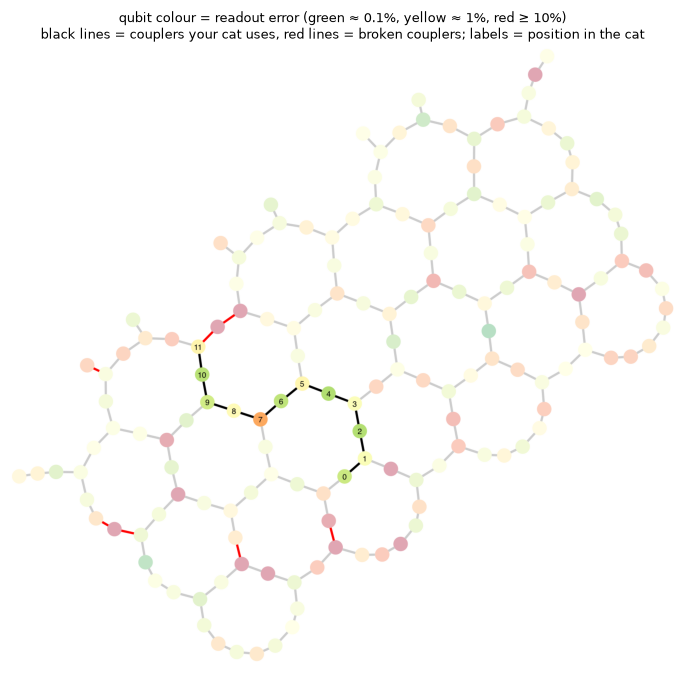

In [18]:
if len(my_line) != N or not is_line(backend, my_line):
    print("⚠️ my_line is not a valid 12-qubit chain yet, so we use the optimization_level=3 choice for now")
    my_line = hc.cat_report(generate_preset_pass_manager(optimization_level=3, backend=backend, seed_transpiler=1)
                            .run(hc.ghz_linear(N)), backend)["qubits"]

pass_manager = generate_preset_pass_manager(optimization_level=3, backend=backend, initial_layout=my_line,
                                            seed_transpiler=1)
line_cat = pass_manager.run(hc.ghz_linear(N))
print(hc.cat_report(line_cat, backend))
hc.show_chip(backend, line_cat);

In [19]:
line_result = hc.measure_cat_quality(line_cat, sim, total_shots=8000)
print("baseline :", baseline_result)
print("your line:", line_result)

baseline : CatResult(N=12: F = 0.442 ± 0.010 [not certified] | P = 0.702 ± 0.007, X = 0.481 ± 0.015)
your line: CatResult(N=12: F = 0.722 ± 0.008 [certified ✓] | P = 0.868 ± 0.006, X = 0.708 ± 0.011)


💡 **Experiment:** what if the 12 qubits do *not* form a chain? Below we take every second qubit of your chain plus some qubits far away. Neighbouring cat qubits are then no longer neighbours on the chip, and the router has to insert SWAP gates to bring them together. Look at the chip map, at `swap_overhead` (each SWAP costs 3 CZs) and at ESP.

{'n': 12,
 'two_qubit_gates': 75,
 'swap_overhead': 64,
 'two_qubit_depth': 63,
 'duration_us': 6.204000000000001,
 'idle_after_entangling_us': 28.66,
 'ESP': 4.919701366699076e-145,
 'qubits': [91, 89, 87, 107, 105, 56, 41, 40, 42, 43, 44, 45]}

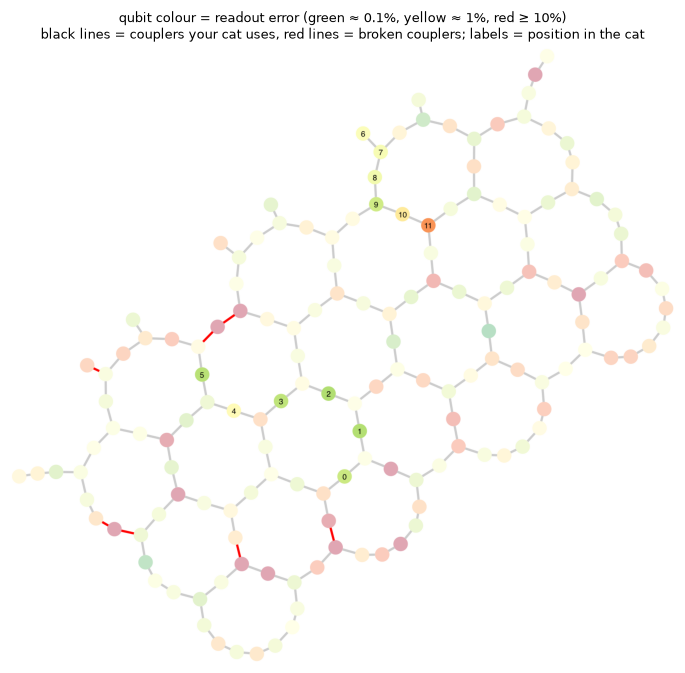

In [20]:
scattered = my_line[::2] + [q for q in range(40, 160) if q not in my_line][: N - len(my_line[::2])]
hc.show_chip(backend, qubits=scattered);     # where the 12 cat qubits start: not a connected chain
scattered_cat = generate_preset_pass_manager(optimization_level=3, backend=backend, initial_layout=scattered,
                                             seed_transpiler=1).run(hc.ghz_linear(N))
hc.cat_report(scattered_cat, backend)

---
# Mission 3 · Grow the cat faster (depth & idle time) 🟡
🎯 *Halve the time your qubits spend waiting.*

A qubit that is still in $|0\rangle$ doesn't mind waiting: $|0\rangle$ has no phase to lose. But once a qubit has joined the cat it is fragile, and every nanosecond it waits for the others it slowly loses its phase ($T_2$ decay). Our chain cat grows from one end (qubit 0) to the other, one CNOT after another, so qubit 0 joins first and then waits for **all 11 remaining CNOTs**.

The **timeline** below shows *when* each gate runs on a 6-qubit chain cat: time goes left to right, one row per qubit. `hc.schedule_circuit(circuit, backend)` works out these times (it is the transpiler's *scheduling* stage) and `hc.measure_cat(cat, "Z")` adds the Z-basis measurement. Look at the staircase of CZ gates, and at how short the circuit is compared with the measurement! The time axis is in units of `dt`, the chip's clock tick, printed above the drawing.

1 dt = 4 ns on fake_kingston


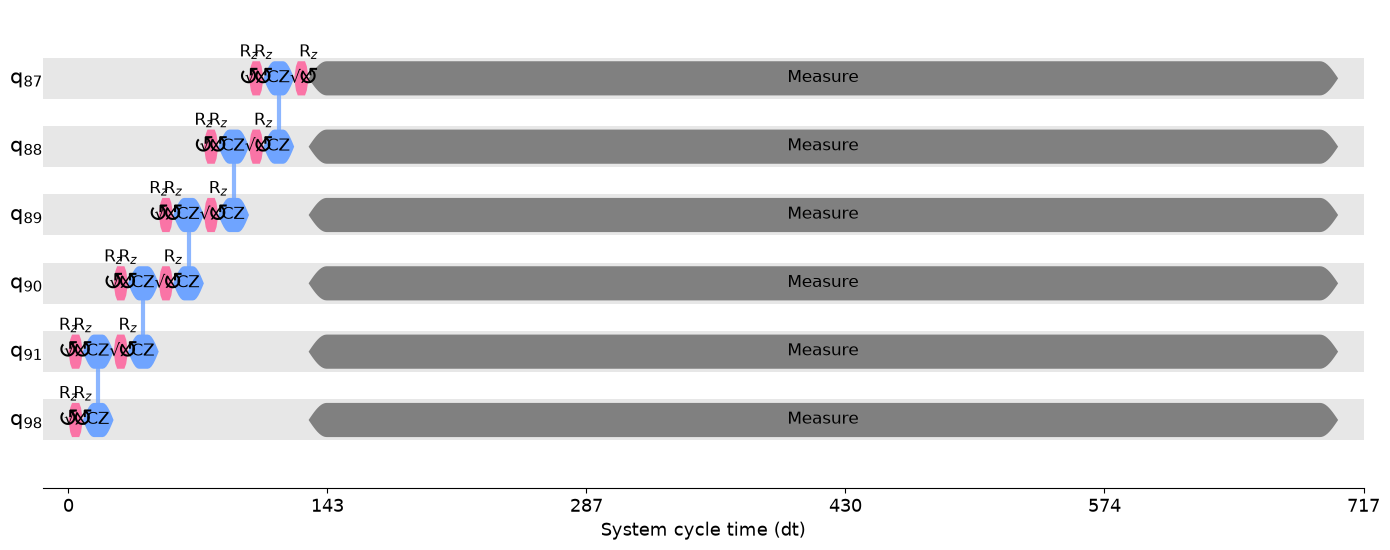

In [21]:
print(f"1 dt = {backend.dt * 1e9:.0f} ns on {backend.name}")
small_cat = generate_preset_pass_manager(optimization_level=3, backend=backend, initial_layout=my_line[:6],
                                         seed_transpiler=1).run(hc.ghz_linear(6))
timeline_drawer(hc.schedule_circuit(hc.measure_cat(small_cat, "Z"), backend), target=backend.target, show_idle=False)

### ✍️ 3a · Start in the middle
Put the Hadamard on the **middle** qubit and grow the cat **in both directions at once**. Same number of CNOTs, half the depth.

✍️ **Pen and paper first:** convince yourself that this gives the same state as the chain from one end. Take $n = 5$, start the Hadamard on qubit 2 and write down the state after each CNOT. (Hint: a CNOT from a qubit that is already part of the cat to a fresh qubit in $|0\rangle$ copies the cat's value onto it: $\tfrac{1}{\sqrt2}(|0\ldots0\rangle|0\rangle + |1\ldots1\rangle|0\rangle) \to \tfrac{1}{\sqrt2}(|0\ldots0\rangle|0\rangle + |1\ldots1\rangle|1\rangle)$. Does it matter on which side the fresh qubit sits?)

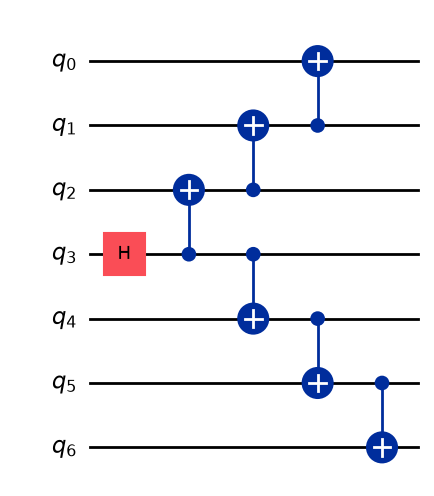

In [22]:
def make_cat_from_middle(n):
    qc = QuantumCircuit(n)
    middle = n // 2
    qc.h(middle)
    left, right = middle, middle
    # The two root operations share a qubit; later branches can run in parallel.
    while left > 0 or right < n - 1:
        if left > 0:
            qc.cx(left, left - 1)
            left -= 1
        if right < n - 1:
            qc.cx(right, right + 1)
            right += 1
    return qc

make_cat_from_middle(7).draw("mpl")


In [23]:
# ✅ Check: still a cat?  (verify_cat runs an exact, noiseless stabilizer simulation)
assert hc.verify_cat(make_cat_from_middle(N), qubits=list(range(N))), "This circuit does not make a cat!"

mid_cat = generate_preset_pass_manager(optimization_level=3, backend=backend, initial_layout=my_line,
                                       seed_transpiler=1).run(make_cat_from_middle(N))
for name, cat in [("grown from one end", line_cat), ("grown from the middle", mid_cat)]:
    report = hc.cat_report(cat, backend)
    print(f"{name:22s} 2q-depth {report['two_qubit_depth']:2d} | idle after entangling "
          f"{report['idle_after_entangling_us']:4.1f} µs | ESP {report['ESP']:.3f}")

grown from one end     2q-depth 11 | idle after entangling  5.9 µs | ESP 0.795
grown from the middle  2q-depth  6 | idle after entangling  2.4 µs | ESP 0.835


In [24]:
mid_result = hc.measure_cat_quality(mid_cat, sim, total_shots=8000)
print("grown from one end   :", line_result)
print("grown from the middle:", mid_result)

grown from one end   : CatResult(N=12: F = 0.722 ± 0.008 [certified ✓] | P = 0.868 ± 0.006, X = 0.708 ± 0.011)
grown from the middle: CatResult(N=12: F = 0.739 ± 0.008 [certified ✓] | P = 0.868 ± 0.005, X = 0.742 ± 0.011)


💭 At 12 qubits the gain is modest: the circuit is short compared with $T_2$. But it grows quickly with the size of the cat. Count the waiting in CNOT steps: in a chain grown from one end, qubit $k$ joins at step $k$ and then waits until the last step, $N-1$. The total waiting time of all qubits is
$$\sum_{k=0}^{N-1} (N-1-k) = \frac{N(N-1)}{2} \;\propto\; N^2 .$$
Twice the qubits, four times the total waiting. Growing from the middle halves each qubit's wait, so the total drops to about $N^2/4$ instead of $N^2/2$: half as much, but still growing like $N^2$. So for big cats (Mission 8) the structure matters a lot. On heavy-hex you can even grow the cat in **three** directions (a *tree*), shown in Mission 8.

---
# Mission 4 · Error suppression: echoes & twirls 🟢
🎯 *Protect idle qubits with dynamical decoupling, and learn what twirling does.*

📚 **Further reading:** IBM's guide [Error mitigation and suppression techniques](https://quantum.cloud.ibm.com/docs/en/guides/error-mitigation-and-suppression-techniques). ⚠️ It switches these techniques on as IBM Runtime options; don't do that here, because `hc.Recipe` already applies them.

### Dynamical decoupling (DD): a trick from NMR
While a qubit waits, its phase slowly drifts, because its frequency is slightly off (by an amount that itself changes only slowly). In a cat the drifts of all $N$ qubits add up, so it loses its phase $N$ times faster than a single qubit.

The fix is an old trick from nuclear magnetic resonance (NMR), the **spin echo** (Erwin Hahn, 1950): flip the qubit by 180° halfway through the wait. After the flip, the same drift pushes the phase *the other way*, so the second half of the wait undoes the first. **Dynamical decoupling (DD)** fills every idle period with such flips: pairs of X pulses, so that the two flips together leave the ideal state unchanged. It only cancels drifts that are slow compared with the time between pulses, and it can't undo energy loss ($T_1$).

`hc.Recipe(dd="XX")` inserts the pulses. The Fall Fest simulator contains slow frequency noise (standard deviation 10 kHz) during idle periods, the kind DD can undo.

### ✍️ 4a · How long does a cat survive? (free decay vs. echo)
The cleanest way to see DD at work: prepare the cat, let it **wait** for $t$ microseconds, then measure, once without and once with echoes. In NMR language you are comparing a *free induction decay* with a *spin echo*. (~2 min)

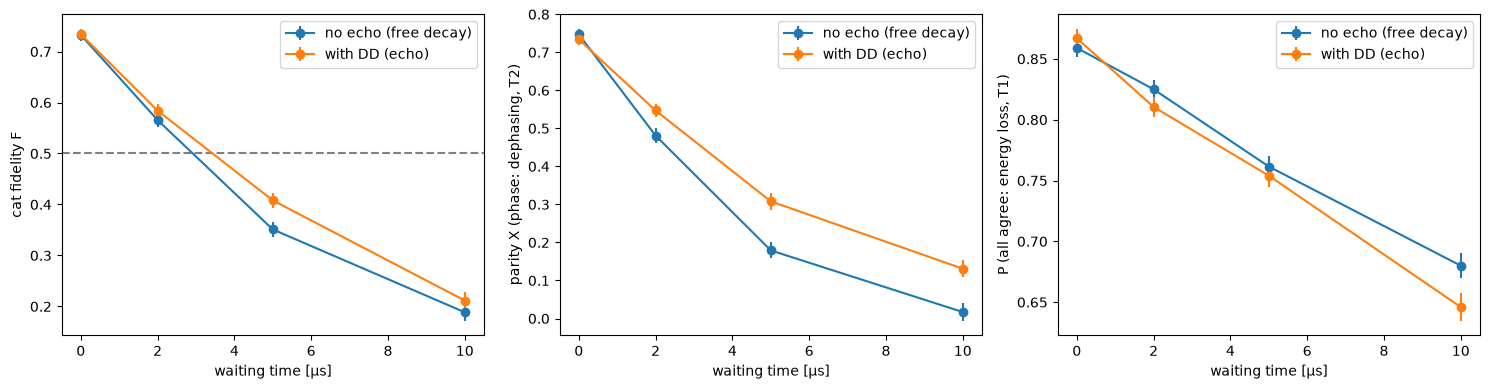

wait  0 µs | no echo: F = 0.73, X = 0.75, P = 0.86 | with DD: F = 0.73, X = 0.73, P = 0.87
wait  2 µs | no echo: F = 0.57, X = 0.48, P = 0.82 | with DD: F = 0.58, X = 0.55, P = 0.81
wait  5 µs | no echo: F = 0.35, X = 0.18, P = 0.76 | with DD: F = 0.41, X = 0.31, P = 0.75
wait 10 µs | no echo: F = 0.19, X = 0.02, P = 0.68 | with DD: F = 0.21, X = 0.13, P = 0.65


In [25]:
qubits = hc.cat_qubits(mid_cat)
waits = [0, 2, 5, 10]                                   # microseconds
memory = {None: [], "XX": []}
for t in waits:
    waited = mid_cat.copy()
    if t > 0:
        waited.delay(t, qubits, unit="us")
    for dd in (None, "XX"):
        memory[dd].append(hc.measure_cat_quality(waited, sim, hc.Recipe(dd=dd), total_shots=4000, qubits=qubits))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for dd, label in [(None, "no echo (free decay)"), ("XX", "with DD (echo)")]:
    ax[0].errorbar(waits, [res.F for res in memory[dd]], yerr=[res.F_err for res in memory[dd]], fmt="o-", label=label)
    ax[1].errorbar(waits, [res.X for res in memory[dd]], yerr=[res.X_err for res in memory[dd]], fmt="o-", label=label)
    ax[2].errorbar(waits, [res.P for res in memory[dd]], yerr=[res.P_err for res in memory[dd]], fmt="o-", label=label)
ax[0].axhline(0.5, ls="--", color="gray"); ax[0].set_ylabel("cat fidelity F")
ax[1].set_ylabel("parity X (phase: dephasing, T2)")
ax[2].set_ylabel("P (all agree: energy loss, T1)")
for panel in ax:
    panel.set_xlabel("waiting time [µs]"); panel.legend()
plt.tight_layout(); plt.show()
for i, t in enumerate(waits):
    free, echo = memory[None][i], memory["XX"][i]
    print(f"wait {t:2d} µs | no echo: F = {free.F:.2f}, X = {free.X:.2f}, P = {free.P:.2f} "
          f"| with DD: F = {echo.F:.2f}, X = {echo.X:.2f}, P = {echo.P:.2f}")


**What does the waiting look like, and where do the echo pulses go?** Below are the timelines of the cat with a 2 µs wait, measured in the X basis, without and with DD. Without DD, the wait is one long empty `Delay` block on every qubit. With DD, the scheduler fills it with X pulses (look for the small boxes inside the delay), placed so that the noise picked up before each pulse is undone after it.

dd = None:


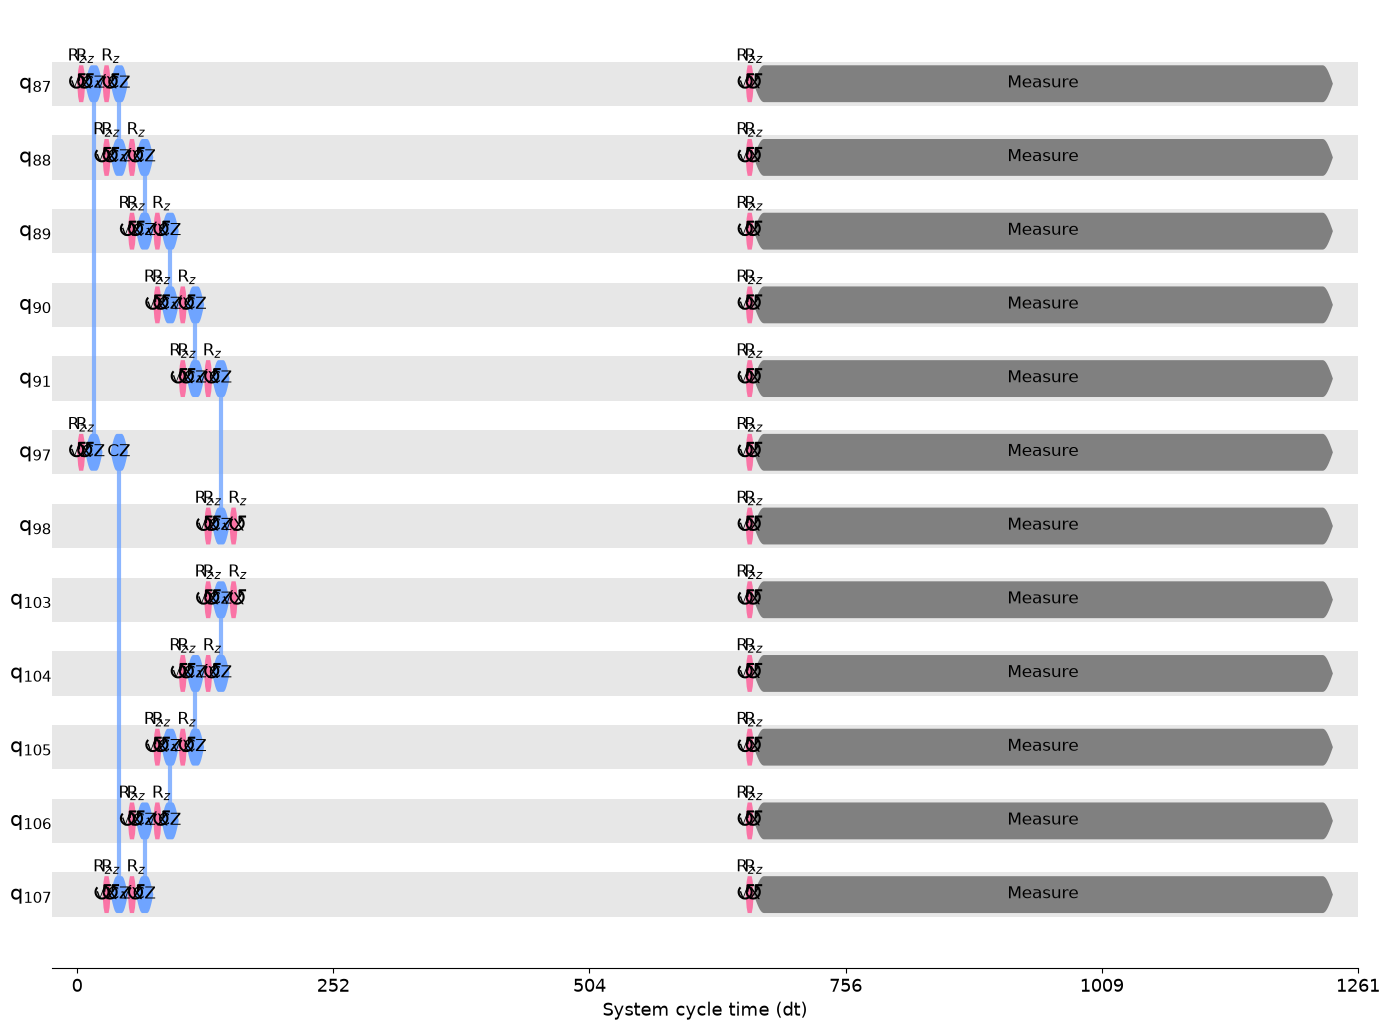

dd = XX:


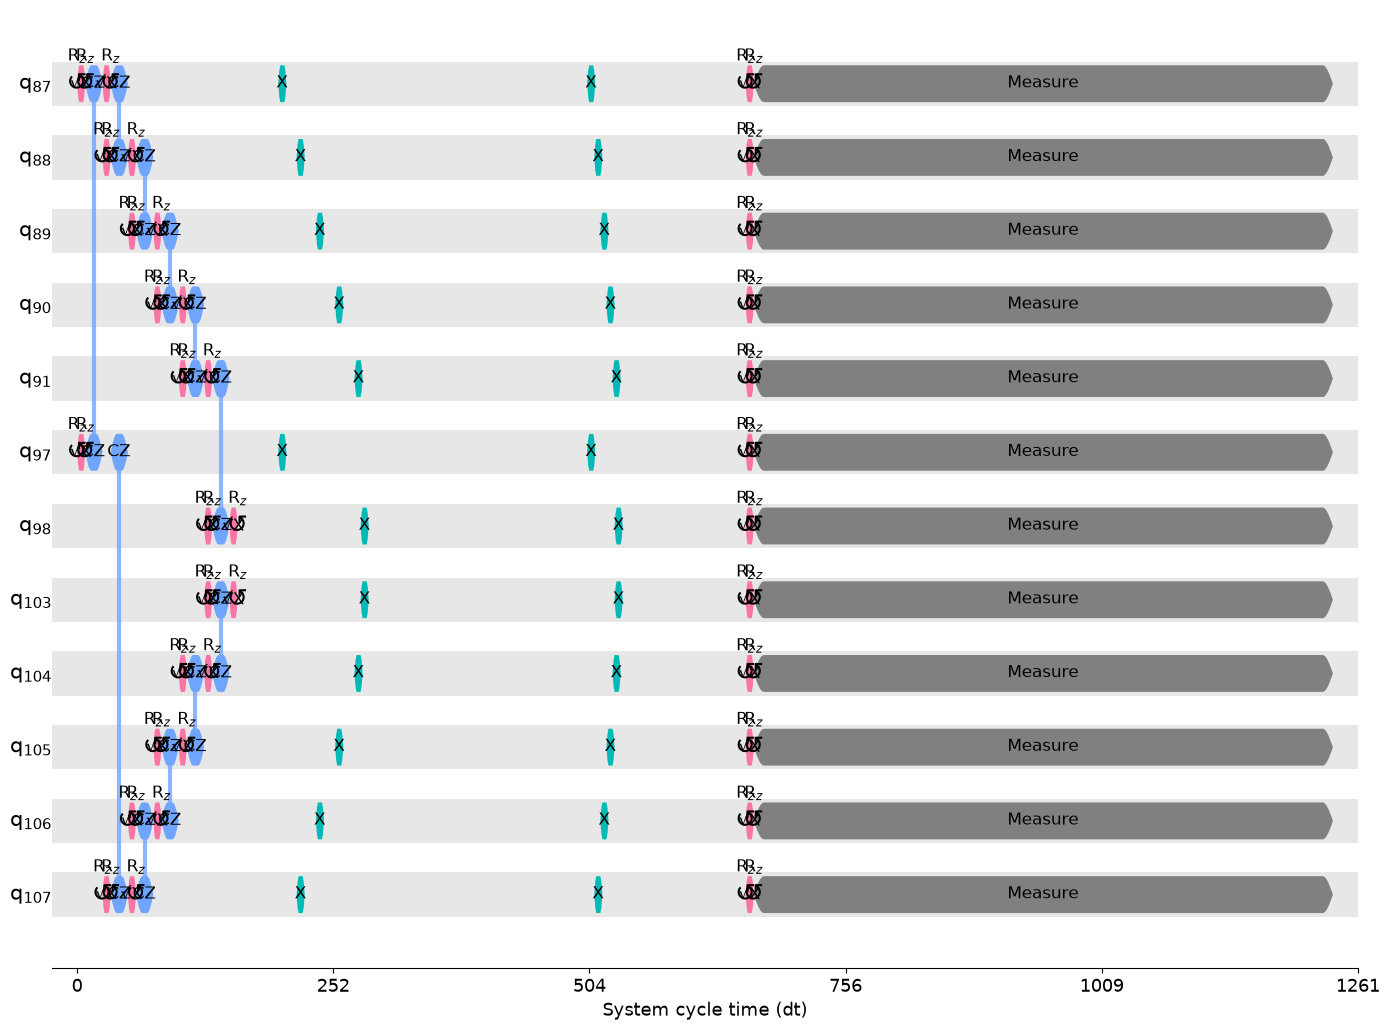

In [26]:
waited_2us = mid_cat.copy()
waited_2us.delay(2, qubits, unit="us")
for dd in (None, "XX"):
    print(f"dd = {dd}:")
    display(timeline_drawer(hc.schedule_circuit(hc.measure_cat(waited_2us, "X"), backend, dd=dd),
                            target=backend.target, show_idle=False))

💭 Two different kinds of noise are at work, and the three panels separate them. **Dephasing** (the middle panel): frequency noise scrambles the *phase* between $|0\ldots0\rangle$ and $|1\ldots1\rangle$, which destroys $X$ but leaves the bits alone. Without echoes the cat's $X$ is gone after ~10 µs; with echoes it lives clearly longer. **Energy loss** (the right panel): qubits relax from 1 to 0, which flips bits and lowers $P$. DD can't help with that, so $P$ drops the same way with and without echoes.

<details>
<summary>🔍 <b>Why does P fall, and why can't DD help?</b> (click to open)</summary>

A qubit in $|1\rangle$ spontaneously relaxes to $|0\rangle$ (on this chip after about 200–300 µs on average). In the $|11\ldots1\rangle$ half of the cat all $N$ qubits are in $|1\rangle$, and a *single* relaxation on any of them breaks "all qubits agree". So that half survives a wait $t$ with probability $\approx e^{-N t/T_1}$, which falls $N$ times faster than for a single qubit: for $N = 12$ and $t = 10$ µs, that half of the cat already loses about 40% of its shots. An echo can't undo relaxation (an X pulse just swaps which half is exposed to it), which is why $P$ drops the same way with and without DD.
</details>

### 4b · DD on your 12-qubit cat
Your cat circuit itself barely waits: the gaps between gates are ~70 ns. Expect DD to change little here. It matters for big chain cats (Mission 8), for circuits with mid-circuit measurements, and often on real hardware, which has noise the simulator lacks (crosstalk, defects).

In [27]:
suppression_results = {}
for dd in (None, "XX"):
    result = hc.measure_cat_quality(mid_cat, sim, hc.Recipe(dd=dd), total_shots=8000)
    suppression_results[dd] = result
    print(f"cat from the middle, dd={str(dd):4s} {result}")


cat from the middle, dd=None CatResult(N=12: F = 0.741 ± 0.007 [certified ✓] | P = 0.872 ± 0.005, X = 0.738 ± 0.011)


cat from the middle, dd=XX   CatResult(N=12: F = 0.733 ± 0.007 [certified ✓] | P = 0.868 ± 0.005, X = 0.730 ± 0.010)


### Pauli twirling
Gate errors come in two flavours.
* **Random (incoherent) errors:** now and then, at random, a gate is followed by an unwanted bit or phase flip (a *Pauli error*). If one gate fails with probability $p$, then $k$ gates fail with probability about $k\,p$.
* **Coherent errors:** the gate does *almost* the right thing, but every time it rotates a little too far, by the same small angle $\epsilon$. Repeated gates add up their angles, so the error grows much faster: about $k^2\epsilon^2$ after $k$ gates instead of $k\,\epsilon^2$ (for $\epsilon = 0.03$ rad and 10 gates: about 9% instead of 1%).

**Twirling** turns any gate error into the first, friendlier kind. Before each CZ we apply random Pauli gates ($I$, $X$, $Y$ or $Z$) to its two qubits, and after the CZ a matching pair that cancels them, so the ideal circuit is unchanged. The error, however, is sandwiched between different random Paulis in every version of the circuit, and averaged over many versions it becomes a random Pauli error with fixed probabilities: one that accumulates less, and that other techniques (like ZNE in Mission 5) can handle.

<details>
<summary>🔍 <b>How can the second pair of Paulis cancel the first, with a CZ in between?</b> (click to open)</summary>

A Pauli that enters a CZ comes out as (possibly different) Paulis. For example, an $X$ on qubit 0 before the CZ has the same effect as an $X$ on qubit 0 **and** a $Z$ on qubit 1 after it: $\text{CZ}\,X_0 = X_0 Z_1\,\text{CZ}$. So if we put $X_0$ before the CZ and $X_0 Z_1$ after it, the two cancel (every Pauli is its own inverse) and only the CZ remains. The same works for every pair of Paulis.
</details>

Here is one random twirl of a single CZ (Qiskit has a function for it), and a check that it does the same as the bare CZ. (You'll see single-qubit rotations instead of named Pauli gates: Qiskit writes them in the chip's native gates.)

same operation as the bare CZ (up to a global phase): True


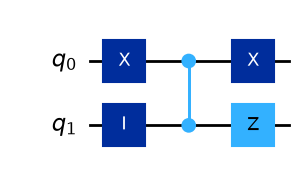

In [28]:
from qiskit.circuit import pauli_twirl_2q_gates
from qiskit.quantum_info import Operator

bare_cz = QuantumCircuit(2)
bare_cz.cz(0, 1)
twirled_cz = pauli_twirl_2q_gates(bare_cz, seed=7)       # one random twirl
print("same operation as the bare CZ (up to a global phase):", Operator(twirled_cz).equiv(Operator(bare_cz)))
twirled_cz.draw("mpl")

`hc.Recipe(gate_twirling=True)` twirls every CZ in your cat and spreads the shots over 16 random versions. The simulator's gate noise is *already* a Pauli channel, so expect no gain here; if anything, the extra Pauli gates (each with its own small error) can cost about 0.01. On real hardware twirling matters, and it makes zero-noise extrapolation (Mission 5) more reliable.

The cell below compares twirling on and off, averaged over three simulator seeds (~1 min).

<details>
<summary>🔍 <b>Why several seeds?</b> (click to open)</summary>

A single run with and without twirling can differ by 2–3 standard deviations just by chance, which looks like an effect but isn't (see "Comparing two results" in Mission 0). The honest test repeats both versions with several simulator seeds and compares the *averages*.
</details>

In [29]:
seeds = [11, 12, 13]
for twirl in (False, True):
    runs = [hc.measure_cat_quality(mid_cat, hc.CatSimulator(backend, seed=seed), hc.Recipe(gate_twirling=twirl),
                                   total_shots=4000) for seed in seeds]
    values = np.array([run.F for run in runs])
    print(f"gate_twirling={str(twirl):5s}: F per seed = {np.round(values, 3)} -> "
          f"mean {values.mean():.3f} ± {values.std(ddof=1) / np.sqrt(len(values)):.3f}")

gate_twirling=False: F per seed = [0.751 0.73  0.734] -> mean 0.738 ± 0.006


gate_twirling=True : F per seed = [0.726 0.716 0.742] -> mean 0.728 ± 0.008


---
# Mission 5 · Error mitigation: fix it in post-processing 🟡
🎯 *Correct readout errors, then extrapolate to zero noise, and learn what it costs.*

### 5a · Readout errors
Prepare nothing (all qubits in $|0\rangle$) and measure. Every `1` you see is a **readout error**.

In [30]:
qubits = hc.cat_qubits(mid_cat)
calibration = hc.measure_cat(mid_cat.copy_empty_like(), "Z", qubits)   # no gates: every qubit is |0>
cal_counts = sim.run(calibration, shots=8000)
print("most frequent outcomes:", dict(sorted(cal_counts.items(), key=lambda kv: -kv[1])[:4]))

most frequent outcomes: {'000000000000': 7168, '000010000000': 200, '000000001000': 81, '100000000000': 79}


In [31]:
shots = sum(cal_counts.values())
p_flip = np.array([sum(count for bits, count in cal_counts.items()
    if bits.replace(" ", "")[-1-i] == "1") / shots for i in range(N)])
print("readout flip probability per cat qubit [%]:", np.round(100*p_flip, 2))


readout flip probability per cat qubit [%]: [0.7  1.   0.31 1.14 0.38 1.11 0.54 2.65 1.03 0.54 0.41 1.12]


**How readout errors shrink the parity.** Write each measured bit as a value $s = +1$ (for `0`) or $s = -1$ (for `1`). Suppose qubit $i$'s result is flipped with probability $p_i$, whatever its true value (we'll come back to this assumption). Then the measured value is the true value $s$ with probability $1 - p_i$ and the wrong value $-s$ with probability $p_i$, so *on average*
$$\langle s_\text{measured}\rangle = (1-p_i)\,s - p_i\,s = (1 - 2p_i)\,s = \lambda_i\, s, \qquad \lambda_i = 1 - 2p_i .$$
Each qubit's value is shrunk towards 0 by the factor $\lambda_i$ (for example $p_i = 2\%$ gives $\lambda_i = 0.96$). The parity is the *product* of all $N$ values, and the flips on different qubits are independent, so the average of the product is the product of the averages:
$$X_\text{measured} = \Big(\prod_i \lambda_i\Big)\, X_\text{true} \quad\Longrightarrow\quad X_\text{true} = \frac{X_\text{measured}}{\prod_i \lambda_i}$$
So if we know the $\lambda_i$, dividing the measured parity by their product gives back the true parity. We call the result $X_\text{corrected}$: it is our estimate of $X_\text{true}$ (only an estimate, because $X_\text{measured}$ and the $p_i$ come from a finite number of shots).
With 12 qubits at $p_i \approx 1\%$, $\prod_i \lambda_i \approx 0.98^{12} \approx 0.78$: readout alone hides about a fifth of the parity.

In [32]:
raw = hc.measure_cat_quality(mid_cat, sim, total_shots=8000)
lambdas = 1 - 2*p_flip
X_corrected = raw.X / np.prod(lambdas)
print(f"raw parity X = {raw.X:.3f} -> corrected X = {X_corrected:.3f}")


raw parity X = 0.721 -> corrected X = 0.899


⚠️ **The catch:** we assumed the flip probability doesn't depend on the true value, but real readout errors are *not* symmetric: a $|1\rangle$ decays to `0` during the measurement more often than a $|0\rangle$ is read as `1`. Our calibration only measured the second kind (we prepared all zeros), so the correction above is slightly off.

The fix is **TREX** (twirled readout error extinction). `hc.Recipe(readout_mitigation=True)` switches it on, for both $X$ *and* $P$. This is also what IBM's Estimator does at `resilience_level=1`.

<details>
<summary>🔍 <b>Optional: how TREX works</b> (click to open)</summary>

1. **Twirl the measurement.** Just before measuring, apply an X gate to a *random* subset of the qubits, and flip those bits back in software afterwards. The ideal result is unchanged. But now each qubit is measured in its true state half of the time and in the opposite state the other half, so the two kinds of readout error get averaged: every qubit behaves as if it had a *symmetric* flip probability $\bar p_i = \tfrac12\big(p_i(1{\to}0) + p_i(0{\to}1)\big)$. That makes the assumption behind the division above exactly true. (This is the same randomization idea as gate twirling in Mission 4, applied to the measurement instead of the CZ gates.)
2. **Calibrate with the same twirl.** Run extra circuits that prepare all zeros, with the same random X pattern before measuring. The true value of every product of $Z$s is then $+1$, so the measured averages give the shrink factors $\lambda_i$ directly, including the asymmetry.
3. **Divide.** Correct every quantity by the matching product of $\lambda$s. For $X$, that is the division above. For $P$ it takes one more step: "all qubits agree" can be written as an average of products of $Z$ values over all *even-sized* groups of qubits,
$P = \frac{1}{2^{N-1}} \sum_{|S|\ \text{even}} \big\langle \textstyle\prod_{i\in S} Z_i \big\rangle$, and each product is divided by $\prod_{i\in S}\lambda_i$. The toolkit does this efficiently shot by shot (`_mitigated_estimates` in `herding_cats.py`).

Original paper: [van den Berg, Minev & Temme, *PRA* 105, 032620 (2022)](https://arxiv.org/abs/2012.09738).

**The price:** dividing by small numbers amplifies the statistical noise as well, so the error bars of corrected values are bigger than the raw ones (here roughly 2×). If some $\lambda_i$ is close to 0 (a qubit that is read out almost at random), the error bars explode, and the toolkit warns you.
</details>

In [33]:
trex = hc.measure_cat_quality(mid_cat, sim, hc.Recipe(readout_mitigation=True), total_shots=8000)
print("raw :", raw)
print("TREX:", trex)

raw : CatResult(N=12: F = 0.733 ± 0.008 [certified ✓] | P = 0.873 ± 0.005, X = 0.721 ± 0.011)
TREX: CatResult(N=12: F = 0.930 ± 0.016 [certified ✓] | P = 0.970 ± 0.010, X = 0.921 ± 0.020)


### 5b · Zero-noise extrapolation (ZNE)
We can't remove gate noise, but we can **amplify** it on purpose: replace every CZ by CZ·CZ·CZ (×3: the same ideal result, since CZ·CZ = identity, but three times the gate noise) or by 5 CZs (×5). `hc.fold_cz(cat, factor)` does this replacement. Then measure at noise ×1, ×3, ×5 and **extrapolate back to ×0**. (Proposed in [Temme, Bravyi & Gambetta, *PRL* 119, 180509 (2017)](https://arxiv.org/abs/1612.02058).)

**What exactly are we extrapolating?** ZNE is a method for *expectation values*: averages of a measured observable, such as the magnetization of a spin model. Our cat score is built from two of them: $X$ is the expectation value of the observable $X\otimes X\otimes\cdots\otimes X$, and $P$ is the expectation value of the projector onto "all 0 or all 1". $F = P + (X-1)/2$ is a fixed combination of the two, so extrapolating $P$ and $X$ (or $F$ directly) is legitimate.

But be clear about what the result means. Mitigation does **not** make the state on the chip any better: the qubits are exactly as noisy as before. It gives an *estimate* of the value a noiseless chip would have produced. Here we know that value in advance: a perfect cat has $P = X = F = 1$. So "how close does mitigated $F$ get to 1, and with what error bar" measures **how well your error mitigation works**, which is what the Cleanest Cat score rewards. In real applications the ideal value is unknown, and that is when an accurate, well-tested mitigation method pays off.

In [34]:
factors = [1, 3, 5]
zne_points = [hc.measure_cat_quality(hc.fold_cz(mid_cat, factor), sim, hc.Recipe(readout_mitigation=True),
                                     total_shots=8000, qubits=qubits) for factor in factors]
for factor, result in zip(factors, zne_points):
    print(f"noise ×{factor}: {result}")

noise ×1: CatResult(N=12: F = 0.921 ± 0.017 [certified ✓] | P = 0.968 ± 0.009, X = 0.906 ± 0.021)
noise ×3: CatResult(N=12: F = 0.838 ± 0.016 [certified ✓] | P = 0.934 ± 0.010, X = 0.806 ± 0.020)
noise ×5: CatResult(N=12: F = 0.772 ± 0.019 [certified ✓] | P = 0.899 ± 0.011, X = 0.745 ± 0.025)


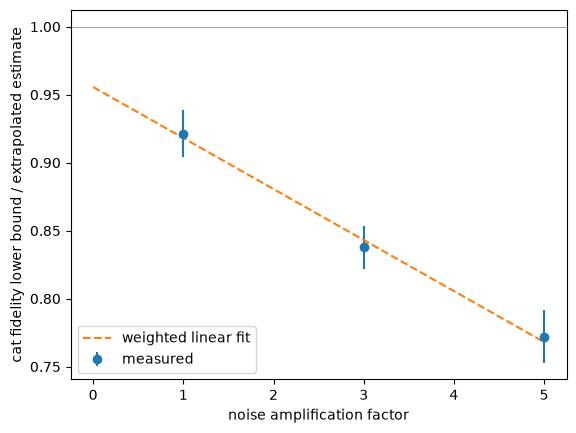

zero-noise estimate: F = 0.956


In [35]:
F_values = np.array([r.F for r in zne_points])
F_errors = np.array([r.F_err for r in zne_points])
slope, F_zero = np.polyfit(factors, F_values, 1, w=1/np.maximum(F_errors, 1e-9))
factor_grid = np.linspace(0, 5, 50)
plt.errorbar(factors, F_values, yerr=F_errors, fmt="o", label="measured")
plt.plot(factor_grid, F_zero+slope*factor_grid, "--", label="weighted linear fit")
plt.axhline(1, color="gray", lw=0.5)
plt.xlabel("noise amplification factor"); plt.ylabel("cat fidelity lower bound / extrapolated estimate")
plt.legend(); plt.show()
print(f"zero-noise estimate: F = {F_zero:.3f}")


In [36]:
# The toolkit does the same (it extrapolates P and X separately; 'linear', 'exponential' or 'quadratic')
for kind in ("linear", "exponential", "quadratic"):
    result = hc.measure_cat_quality(mid_cat, sim, hc.Recipe(readout_mitigation=True, zne_factors=(1, 3, 5),
                                                            zne_extrapolator=kind), total_shots=8000)
    print(f"TREX + ZNE ({kind:11s}):", result)

TREX + ZNE (linear     ): CatResult(N=12: F = 0.951 ± 0.028 [certified ✓] | P = 0.983 ± 0.016, X = 0.935 ± 0.040)


TREX + ZNE (exponential): CatResult(N=12: F = 1.052 ± 0.032 [certified ✓] | P = 1.008 ± 0.018, X = 1.088 ± 0.043)


TREX + ZNE (quadratic  ): CatResult(N=12: F = 0.903 ± 0.044 [certified ✓] | P = 0.927 ± 0.029, X = 0.951 ± 0.063)


💭 **ZNE + gate twirling.** On real hardware, ZNE is almost always combined with gate twirling, and `gate_twirling=True` is worth considering for your Mission 7 run whenever your recipe uses ZNE. In the simulator the gate noise is already Pauli, so twirling should change nothing beyond shot noise: check it below. Compare the results *using the error bars*: with $\sigma_F \approx 0.03$ each, differences up to about 0.08 are just noise (this also goes for linear vs. exponential above). Mitigated values can land above 1, too: $F = 1.05 \pm 0.03$ is perfectly consistent with 1.

<details>
<summary>🔍 <b>Why does ZNE need twirling?</b> (click to open)</summary>

Folding assumes that three CZs carry three times the noise of one. That's true for random (Pauli) errors, but a *coherent* over-rotation adds up its angle: three times the angle gives about nine times the error, and the extrapolation goes wrong. Twirling turns coherent errors into Pauli errors first (Mission 4), so the noise really does grow in proportion to the number of CZs.
</details>

In [37]:
result = hc.measure_cat_quality(mid_cat, sim, hc.Recipe(readout_mitigation=True, zne_factors=(1, 3, 5),
                                                        gate_twirling=True), total_shots=8000)
print("TREX + ZNE + gate twirling:", result)

TREX + ZNE + gate twirling: CatResult(N=12: F = 0.973 ± 0.030 [certified ✓] | P = 0.995 ± 0.018, X = 0.956 ± 0.039)


### 5c · There is no free lunch
Mitigation removes **bias** (a systematic shift of $F$ away from its true value) but adds **variance** (bigger error bars $\sigma_F$): the corrected numbers are noisier, and ZNE splits your shots over three noise levels. So we judge a recipe by both together, the **conservative error**
$$\varepsilon^* = |1-F| + \sigma_F ,$$
the distance of your measured $F$ from the ideal value 1, plus its error bar. Smaller is better, and it is computed at a **fixed shot budget** (the same total number of shots for every recipe), so you can't win by simply running more shots. A recipe that lands on $F = 1.00 \pm 0.10$ ($\varepsilon^* = 0.10$) is worse than one with $F = 0.96 \pm 0.01$ ($\varepsilon^* = 0.05$)! `hc.conservative_error(result)` computes $\varepsilon^*$.

In [38]:
budget = 24_000
for name, recipe in {
    "raw":                      hc.Recipe(),
    "TREX":                     hc.Recipe(readout_mitigation=True),
    "TREX + ZNE(1,3) linear":   hc.Recipe(readout_mitigation=True, zne_factors=(1, 3), zne_extrapolator="linear"),
    "TREX + ZNE(1,3,5) exp.":   hc.Recipe(readout_mitigation=True, zne_factors=(1, 3, 5)),
}.items():
    result = hc.measure_cat_quality(mid_cat, sim, recipe, total_shots=budget)
    print(f"{name:24s} F = {result.F:.3f} ± {result.F_err:.3f}   ->   eps* = {hc.conservative_error(result):.3f}")

raw                      F = 0.740 ± 0.004   ->   eps* = 0.265


TREX                     F = 0.934 ± 0.010   ->   eps* = 0.075


TREX + ZNE(1,3) linear   F = 0.967 ± 0.016   ->   eps* = 0.049


TREX + ZNE(1,3,5) exp.   F = 0.957 ± 0.016   ->   eps* = 0.059


---
# 🏆 How you are scored
Now that you know $F$, $\sigma_F$, $\varepsilon^*$ and the baseline, here is the full scoring table.

| | What | How it is measured | Points |
|---|---|---|---|
| 🧼 | **Cleanest Cat**, simulator | Your 12-qubit cat + recipe, re-run by the organizers on the Fall Fest simulator (secret seed, 100,000 shots), next to the baseline cat. | 25 |
| 🧼 | **Cleanest Cat**, real hardware | Your final job on **ibm_kingston** (Mission 7). The baseline cat runs **in the same job**, so a bad calibration day affects everyone equally. | 15 |
| 🦁 | **Biggest Cat** | Largest $N$ whose entanglement you *certify* ($F - 2\sigma_F > 0.5$) from raw or readout-corrected data, **without ZNE** (Mission 8 explains why): 16 / 24 / 32 / 40 / 48+ qubits give 3 / 6 / 9 / 12 / 15 points. Full points on hardware, half on the simulator. | 15 |
| ✅ | **Missions 0–5 done** | All cells run, outputs visible, ✍️ parts done (2 points each for Missions 1–5) | 10 |
| 🧠 | **Understanding** | Four short answers (end of notebook) | 20 |
| 🔬 | **Evidence** | Your "what helped and by how much" table (Mission 6) | 10 |
| 🎤 | **Clarity** | A notebook the judges can follow | 5 |

**Cleanest Cat points.** We compare your conservative error $\varepsilon^* = |1-F| + \sigma_F$ (Mission 5c) with the error of the baseline cat, $|1 - F_\text{baseline}|$ (about 0.6 on the simulator). The ratio is your **error-reduction factor**
$$R = \frac{|1-F_\text{baseline}|}{\varepsilon^*} ,$$
so $R = 4$ means "four times closer to a perfect cat than the baseline". Points grow with the logarithm of $R$ (every doubling of $R$ is worth the same) and reach the maximum at $R = 16$:
$$\text{points} = \text{max points} \times \min\!\left(1,\ \frac{\log R}{\log 16}\right).$$
For example, $R = 2$ gives 25 % of the points, $R = 4$ gives 50 % and $R \ge 16$ gives 100 %.

---
# Mission 6 · Your Cleanest Cat (N = 12) 🟡
🎯 *Combine everything into one circuit + one recipe, and check its score.*

The organizers will run **your 12-qubit cat for `fake_kingston`** with **your recipe** on the Fall Fest simulator with a **secret seed** and 100,000 shots, next to the baseline cat. `hc.scorecard(cat, recipe, simulator)` does the same with a simulator seed you choose and a smaller shot budget (24,000), and returns both results, $\varepsilon^*$, $R$ and the estimated points. Change the simulator seed to check that your result is robust, not lucky.

⭐ Ideas:
* add a $T_2$ cost to your chain search, so that the qubits that wait longest are the ones with long $T_2$ (Mission 2);
* a tree-shaped 12-qubit cat (Mission 8);
* the best ZNE factors and extrapolator: `zne_extrapolator` can be `"linear"`, `"exponential"` or `"quadratic"` (the last needs three or more factors);
* combining ZNE with gate twirling and DD (mainly for hardware).

**What counts for the score.** The organizers re-run your recipe with their own copy of the toolkit, so your Cleanest Cat score can only use what `hc.Recipe` offers. Don't edit `herding_cats.py`: changes won't reach the grader. Ideas beyond the toolkit, such as your own extrapolation fit or another mitigation method, are very welcome as **exploration**: put them in your notebook and your evidence table. They count for the judged points (🔬 Evidence, 🧠 Understanding), not for the automatic score. Some starting points are in Mission 8 under "Frontier ideas".

In [39]:
# Independent circuit/recipe search. All screening recipes get a nominal 12k shots;
# the top three are compared on fresh seeds with 24k shots each.
my_clean_cat, my_recipe, search_rows, finalists, choice = qats.optimize_clean(backend, mid_cat, sim)
hc.save_circuit(my_clean_cat, "my_clean_cat.qpy")
assert len(hc.cat_qubits(my_clean_cat)) == 12 and hc.verify_cat(my_clean_cat)
print("Selected:", choice["circuit"], choice["technique"])
print("Fresh-seed mean conservative error:", choice["validation_error"])


screen middle / TREX: CatResult(N=12: F = 0.919 ± 0.013 [certified ✓] | P = 0.959 ± 0.008, X = 0.921 ± 0.016)


screen middle / DD + TREX: CatResult(N=12: F = 0.933 ± 0.014 [certified ✓] | P = 0.984 ± 0.008, X = 0.898 ± 0.017)


screen middle / TREX + twirling: CatResult(N=12: F = 0.925 ± 0.013 [certified ✓] | P = 0.968 ± 0.008, X = 0.914 ± 0.015)


screen middle / TREX + ZNE linear: CatResult(N=12: F = 0.997 ± 0.022 [certified ✓] | P = 1.008 ± 0.013, X = 0.977 ± 0.028)


screen middle / TREX + ZNE exponential: CatResult(N=12: F = 0.948 ± 0.026 [certified ✓] | P = 0.969 ± 0.016, X = 0.958 ± 0.032)


screen middle / DD + TREX + ZNE + twirling: CatResult(N=12: F = 0.977 ± 0.027 [certified ✓] | P = 1.003 ± 0.015, X = 0.950 ± 0.035)


... (15 outputs left out)

holdout tree / DD + TREX + ZNE + twirling, seed 702: CatResult(N=12: F = 1.024 ± 0.019 [certified ✓] | P = 1.010 ± 0.012, X = 1.027 ± 0.024)


holdout timing-aware middle / TREX + ZNE linear, seed 701: CatResult(N=12: F = 0.964 ± 0.016 [certified ✓] | P = 0.983 ± 0.010, X = 0.962 ± 0.022)


holdout timing-aware middle / TREX + ZNE linear, seed 702: CatResult(N=12: F = 0.969 ± 0.015 [certified ✓] | P = 0.990 ± 0.009, X = 0.959 ± 0.021)


Selected: tree DD + TREX + ZNE + twirling
Fresh-seed mean conservative error: 0.03526823658605788


In [40]:
card = hc.scorecard(my_clean_cat, my_recipe, hc.CatSimulator(seed=1))
for key, value in card.items():
    print(f"{key:15s}: {value}")

baseline       : CatResult(N=12: F = 0.407 ± 0.006 [not certified] | P = 0.691 ± 0.004, X = 0.431 ± 0.008)
team           : CatResult(N=12: F = 0.976 ± 0.017 [certified ✓] | P = 0.988 ± 0.011, X = 0.977 ± 0.022)
eps_star       : 0.0409447804923465
R              : 14.493096788675901
points (of 25) : 24.1


In [41]:
# Robustness: same cat, different simulator seeds (quicker, 8k shots)
for seed in (2, 3):
    seed_card = hc.scorecard(my_clean_cat, my_recipe, hc.CatSimulator(seed=seed), total_shots=8000)
    print(f"seed {seed}: F = {seed_card['team'].F:.3f} ± {seed_card['team'].F_err:.3f}, "
          f"R = {seed_card['R']:.1f}, points ≈ {seed_card['points (of 25)']}")

seed 2: F = 0.948 ± 0.033, R = 7.0, points ≈ 17.6


seed 3: F = 0.975 ± 0.030, R = 10.9, points ≈ 21.6


In [42]:
# Equal nominal 8k-shot ablation; actual shots can round down by < circuit count.
dd_trex = hc.measure_cat_quality(mid_cat, sim,
    hc.Recipe(dd="XX", readout_mitigation=True), total_shots=8000)
dd_trex_zne = hc.measure_cat_quality(mid_cat, sim,
    hc.Recipe(dd="XX", readout_mitigation=True, zne_factors=(1,3,5)), total_shots=8000)
evidence = [
    ("Baseline", baseline_result, "Default layout, one-ended chain"),
    ("Better layout", line_result, "Search connected low-error qubits and couplers"),
    ("Grow from middle", mid_result, "Parallel branches shorten fragile idle time"),
    ("+ DD", suppression_results["XX"], "Echo slow phase drift; added pulses can also hurt"),
    ("+ TREX", dd_trex, "Calibrate readout and undo random measurement flips"),
    ("+ ZNE", dd_trex_zne, "Extrapolate factors 1,3,5; this is a zero-noise estimate"),
]
display(HTML("<h3>Qats evidence: nominal 8,000 shots per step</h3><table><tr>"
    "<th>Step</th><th>F ± standard error</th><th>Actual shots</th><th>Explanation</th></tr>" +
    "".join(f"<tr><td>{name}</td><td>{r.F:.4f} ± {r.F_err:.4f}</td><td>{r.shots}</td><td>{why}</td></tr>"
    for name,r,why in evidence) + "</table>"))
qats.dump("evidence.json", [{"step": name, "result": qats.result_dict(r), "why": why}
    for name,r,why in evidence])
print("PEC stretch: not claimed or used for scoring. Learning a credible gate-noise inverse would require")
print("extra calibration and quasiprobability sampling; TREX and validated ZNE fit the event budget.")


Step,F ± standard error,Actual shots,Explanation
Baseline,0.4420 ± 0.0104,8000,"Default layout, one-ended chain"
Better layout,0.7218 ± 0.0083,8000,Search connected low-error qubits and couplers
Grow from middle,0.7392 ± 0.0078,8000,Parallel branches shorten fragile idle time
+ DD,0.7328 ± 0.0071,8000,Echo slow phase drift; added pulses can also hurt
+ TREX,0.9066 ± 0.0165,7968,Calibrate readout and undo random measurement flips
+ ZNE,0.9945 ± 0.0317,7952,"Extrapolate factors 1,3,5; this is a zero-noise estimate"


PEC stretch: not claimed or used for scoring. Learning a credible gate-noise inverse would require
extra calibration and quasiprobability sampling; TREX and validated ZNE fit the event budget.


---
# Mission 7 · 🚀 The real thing: ibm_kingston
🎯 *Run your cat, and the baseline cat, on a real 156-qubit IBM Heron.*

**Before you start**
* You need an IBM Quantum account (free Open Plan) saved on this computer:
  `QiskitRuntimeService.save_account(token="<API key>", instance="<instance CRN>", set_as_default=True)` (do it once, never share your key).
* **Budget:** 10 QPU-minutes per person per 28 days (see the table below). What *does* take long is **the queue**: submit early!
* Do a **test flight** (7.0) as soon as you reach this mission, ideally before 16:30, to check your account and see the queue.
* Hardware cells only run when you set `RUN_HARDWARE = True`. That stops anyone using QPU minutes by accident.

**How much QPU time will we use?** IBM bills roughly *2 s per job + 0.3 ms per shot*. One shot is one run of one circuit, and each run is followed by a fixed **250 µs pause** while the qubits reset. Our circuits themselves are tiny by comparison: a 12-qubit cat including its measurement takes about 3 µs, a 48-qubit tree cat about 4 µs. So the QPU time is set almost entirely by the **number of shots**, not by the size of the cat: going from 12 to 48 qubits adds well under 1%. For the jobs in this notebook:

| Job | Shots | Estimated QPU time |
|---|---|---|
| 7.0 test flight | 2 × 500 | ≈ 2–3 s |
| 7.2 final job (baseline + your cat) | ≈ 40,000 | ≈ 12–20 s |
| Mission 8 big cat (optional, any size) | 40,000 | ≈ 12–20 s |

(The range covers the difference between our estimate and IBM's rule of thumb. Very deep circuits, or recipes with ZNE, which make circuits longer, would add a little more.)

Even a full afternoon uses well under a minute per team. Before every submission the notebook prints an estimate (`hc.estimate_qpu_seconds(circuits, shots, backend)`), and afterwards the time you were actually billed (`hc.job_usage_seconds(job)`). You can also see your usage on the IBM Quantum dashboard.

In [57]:
# Opt-in environment flag; rerunning saved cells reuses job IDs rather than resubmitting.
RUN_HARDWARE = os.environ.get("QATS_RUN_HARDWARE") == "1"
hardware_record = None


### 7.0 · Test flight (tiny job)
`hc.connect_to_hardware("ibm_kingston")` logs in with your saved account and returns the real backend (it plays the role `backend` played so far). `hc.build_cat_experiment(cat, backend, recipe)` makes the list of circuits a recipe needs (Z- and X-basis measurements, plus calibration and random versions if mitigation is on) without running them; `.analyze(counts)` turns the results back into $F$. `hc.HardwareRunner(backend).submit(circuits, shots)` sends them to IBM as **one** job and returns immediately: the job waits in the queue while you keep working.

In [58]:
if RUN_HARDWARE:
    from qiskit_ibm_runtime import QiskitRuntimeService
    service = QiskitRuntimeService()
    real = service.backend("ibm_kingston")
    print(real.name, "|", real.num_qubits, "qubits | jobs waiting:", real.status().pending_jobs)
    test = hc.build_cat_experiment(hc.baseline_cat(real, 4), real)
    test_job = qats.submit_once("test_flight", test.circuits, 500, real)
    print("test job id:", test_job.job_id())


ibm_kingston | 156 qubits | jobs waiting: 6
Estimated QPU use: 2.3s


Submitted test_flight: dbpjnkgou4as73ctq5g0


test job id: dbpjnkgou4as73ctq5g0


In [59]:
if RUN_HARDWARE:
    print(test_job.status())     # QUEUED -> RUNNING -> DONE ; re-run this cell to refresh
    if str(test_job.status()).endswith("DONE"):
        print(test.analyze(hc.HardwareRunner.counts_from_result(test_job.result())))
        print("QPU time billed [s]:", hc.job_usage_seconds(test_job))

QUEUED


### 7.1 · Re-optimize for *today's* calibration
The real chip is re-calibrated several times a day, so today's bad qubits are not the ones in `fake_kingston`, whose calibration data was recorded on 15 April 2026. Re-run your layout search on the **live** backend, which reports today's calibration. Your recipe can stay the same.

**Trial run:** the cell also runs the full job on the simulator first (using the snapshot), so you can be sure everything works before spending QPU time.

In [60]:
live_recipe = my_recipe
rehearsal = hc.FinalJob(my_clean_cat, live_recipe, backend, total_shots=32_000)
baseline_rehearsal, team_rehearsal = rehearsal.analyze(sim.run(rehearsal.circuits, rehearsal.shots))
print(f"rehearsal: baseline F={baseline_rehearsal.F:.3f}, ours={team_rehearsal.F:.3f} ± {team_rehearsal.F_err:.3f}")
assert hc.verify_cat(my_clean_cat) and team_rehearsal.F > 0.5
if RUN_HARDWARE:
    # Re-search the current calibration. Compare timing-aware tree and middle chain.
    live_line = find_good_line(real, N)
    live_middle = generate_preset_pass_manager(optimization_level=3, backend=real,
        initial_layout=live_line, seed_transpiler=1).run(make_cat_from_middle(N))
    live_tree = qats.best_tree_cat(real, N)
    live_cat = max([c for c in (live_middle, live_tree) if c is not None],
        key=lambda c: hc.cat_report(c, real)["ESP"])
    assert hc.verify_cat(live_cat)
    print("Live calibration choice:", hc.cat_report(live_cat, real))
    hc.save_circuit(live_cat, "qats_results/live_clean_cat.qpy")


rehearsal: baseline F=0.406, ours=1.012 ± 0.018


Live calibration choice: {'n': 12, 'two_qubit_gates': 11, 'swap_overhead': 0, 'two_qubit_depth': 6, 'duration_us': 0.536, 'idle_after_entangling_us': 1.3, 'ESP': 0.8766191741879499, 'qubits': [65, 77, 64, 66, 85, 63, 67, 62, 56, 68, 57, 61]}


### 7.2 · Submit the final job (baseline + your cat in **one** job)
`hc.FinalJob(your_cat, your_recipe, backend)` puts the baseline cat (measured raw, as always) and your cat with your recipe into a single job of about 40,000 shots, so both see exactly the same chip at the same moment. `final.save(...)` writes everything needed to analyse the job later into `final_job.json`, so a crashed kernel or a long queue costs you nothing.

In [2]:
if RUN_HARDWARE:
    final_path = Path("qats_results/final_job.json")
    if final_path.exists():
        final = hc.FinalJob.load(str(final_path), real)
    else:
        final = hc.FinalJob(live_cat, live_recipe, real, total_shots=32_000)
        final.save(str(final_path))
    print(f"{len(final.circuits)} circuits × {final.shots} shots = {final.total_shots} shots")
    final_job = qats.submit_once("clean_cat", final.circuits, final.shots, real)
    final.save(str(final_path), job_id=final_job.job_id())
    print("Submitted clean cat:", final_job.job_id())


150 circuits × 214 shots = 32100 shots
Resuming clean_cat: dbpjo8s4148s739uodm0


Submitted clean cat: dbpjo8s4148s739uodm0


### 7.3 · Collect the results (also works after a kernel restart)

In [63]:
if RUN_HARDWARE:
    print("Waiting for clean-cat hardware job:", final_job.job_id(), flush=True)
    hw_counts = hc.HardwareRunner.counts_from_result(final_job.result())
    qats.dump("clean_hardware_counts.json", hw_counts)
    base_hw, team_hw = final.analyze(hw_counts)
    hardware_record = final.record(final_job.job_id(), hw_counts)
    qats.dump("hardware_record.json", hardware_record)
    print("baseline (same job):", base_hw)
    print("Qats:", team_hw)
    print("error reduction:", hc.error_reduction(base_hw, team_hw))
    print("QPU time billed [s]:", hc.job_usage_seconds(final_job))


Waiting for clean-cat hardware job: dbpjo8s4148s739uodm0


baseline (same job): CatResult(N=12: F = 0.584 ± 0.009 [certified ✓] | P = 0.780 ± 0.006, X = 0.606 ± 0.013)
Qats: CatResult(N=12: F = 0.907 ± 0.017 [certified ✓] | P = 0.947 ± 0.011, X = 0.922 ± 0.020)
error reduction: 3.8049831698956877


QPU time billed [s]: 11.0


---
# Mission 8 · 🦁 The Biggest Cat 🟠
🎯 *How many qubits can you entangle, provably?*

Your cat counts if it is **certified**: $F - 2\sigma_F > 0.5$, measured **without ZNE**. Readout mitigation (TREX), DD and gate twirling are all allowed.

*Why no ZNE here?* The Cleanest Cat asks how accurately you can *estimate* the ideal result, and ZNE is a fair tool for that (Mission 5b). The Biggest Cat asks a different question: is the state that really exists on the chip entangled across all $N$ qubits? A zero-noise extrapolation describes a hypothetical noiseless chip, so it can't answer that. TREX only removes errors made while *reading out* the qubits, so a TREX-corrected certificate still describes the real state. (ZNE wouldn't help much anyway: for big cats it spreads the shots over several noise levels and inflates the error bars.)

Bigger cats need everything at once: good qubits, short idle times, DD, readout mitigation, and enough shots (error bars grow with $N$). The simulator handles cats of 50+ qubits, but it gets slower as $N$ grows (roughly 5 s per 1,000 shots at $N = 24$, 10 s at $N = 36$), so test with a few thousand shots before a long run.

### Trees grow faster than chains
On heavy-hex, a cat can grow from a **root** in up to three directions. Breadth-first growth keeps the depth around the *radius* of the cat instead of its length. Skip bad qubits and couplers as you grow.

💡 **Trade-off:** strict quality thresholds cut the chip into small islands. On `fake_kingston`, "readout ≤ 3%, CZ ≤ 1%, $T_2$ ≥ 50 µs" leaves no connected region bigger than 20 qubits, while "≤ 5%, ≤ 2%, ≥ 30 µs" leaves one of ~100. Bigger cats force you to accept slightly worse qubits.

In [49]:
def make_tree_cat(backend, root, n, max_readout=0.05, max_cz=0.02, min_t2=30e-6):
    qinfo, errors = quality(backend)
    good = {q for q, p in qinfo.items() if p["readout"] <= max_readout and (p["t2"] or 0) >= min_t2}
    if root not in good:
        return None
    adjacent = {q: set() for q in good}
    for (a, b), error in errors.items():
        if error <= max_cz and a in good and b in good:
            adjacent[a].add(b)
            adjacent[b].add(a)
    order, parents, seen = [root], [], {root}
    queue = deque([root])
    while queue and len(order) < n:
        parent = queue.popleft()
        candidates = sorted(adjacent[parent] - seen, key=lambda q:
            2 * errors[tuple(sorted((q, parent)))] + qinfo[q]["readout"] + 1e-6 / qinfo[q]["t2"])
        for child in candidates:
            if len(order) >= n:
                break
            seen.add(child)
            order.append(child)
            parents.append((parent, child))
            queue.append(child)
    if len(order) != n:
        return None
    logical = QuantumCircuit(n)
    index = {q: i for i, q in enumerate(order)}
    logical.h(0)
    for parent, child in parents:
        logical.cx(index[parent], index[child])
    return generate_preset_pass_manager(optimization_level=3, backend=backend,
        initial_layout=order, seed_transpiler=1).run(logical)


big-cat screen: CatResult(N=24: F = 0.850 ± 0.025 [certified ✓] | P = 0.925 ± 0.016, X = 0.851 ± 0.032)


big-cat screen: CatResult(N=36: F = 0.849 ± 0.039 [certified ✓] | P = 0.908 ± 0.020, X = 0.881 ± 0.054)


big-cat screen: CatResult(N=48: F = 0.754 ± 0.045 [certified ✓] | P = 0.835 ± 0.023, X = 0.836 ± 0.072)


big-cat screen: CatResult(N=64: F = 0.583 ± 0.066 [not certified] | P = 0.800 ± 0.028, X = 0.567 ± 0.117)


big-cat independent confirmation: CatResult(N=48: F = 0.676 ± 0.028 [certified ✓] | P = 0.832 ± 0.013, X = 0.687 ± 0.043)


Largest independently certified simulated candidate: CatResult(N=48: F = 0.676 ± 0.028 [certified ✓] | P = 0.832 ± 0.013, X = 0.687 ± 0.043)
{'n': 48, 'two_qubit_gates': 47, 'swap_overhead': 0, 'two_qubit_depth': 14, 'duration_us': 1.304, 'idle_after_entangling_us': 16.448000000000004, 'ESP': 0.40977572245897786, 'qubits': [89, 90, 78, 91, 69, 98, 68, 70, 111, 67, 71, 110, 57, 66, 58, 109, 65, 51, 108, 118, 77, 64, 50, 52, 107, 129, 85, 63, 49, 53, 106, 97, 128, 130, 62, 56, 38, 39, 54, 105, 87, 61, 43, 29, 33, 55, 104, 117]}


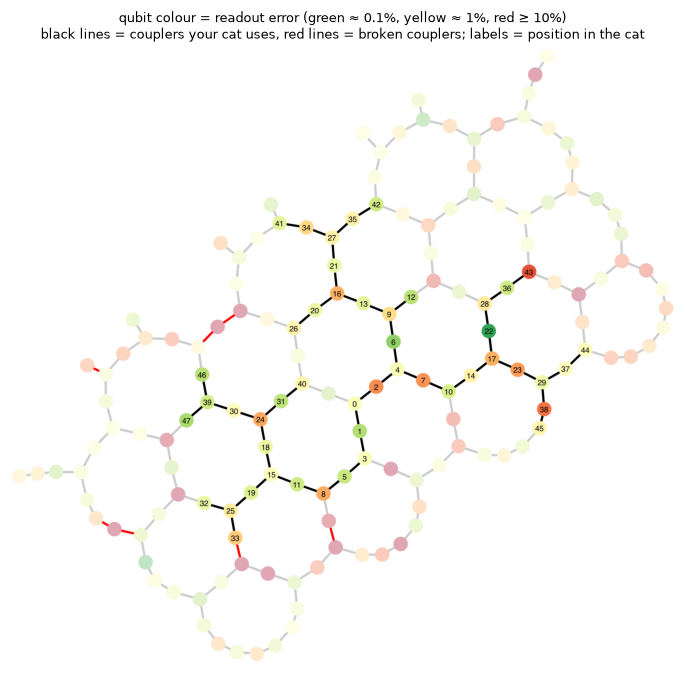

In [50]:
best_tree_cat = qats.best_tree_cat
big_cat, big_sim_exp, big_sim_result, big_search_rows = qats.big_search(backend, sim)
n_big = len(hc.cat_qubits(big_cat))
print("Largest independently certified simulated candidate:", big_sim_result)
print(hc.cat_report(big_cat, backend))
hc.show_chip(backend, big_cat);


In [51]:
big_recipe = big_sim_exp.recipe
big_exp, big_result = big_sim_exp, big_sim_result
big_counts = big_exp.last_counts
big_sim_counts = big_counts
big_where, big_job_id = "simulator", None
qats.dump("big_simulator_record.json", hc.biggest_cat_record(
    big_sim_exp, big_sim_counts, big_sim_result, where="simulator"))
print(big_result)


CatResult(N=48: F = 0.676 ± 0.028 [certified ✓] | P = 0.832 ± 0.013, X = 0.687 ± 0.043)


### On real hardware
Same idea: build the cat for `real`, build the experiment, submit, and analyse later. `hc.save_circuit` / `hc.load_circuit` store a circuit in a file. The experiment's random choices are fixed by `seed=0`, so after a kernel restart you can rebuild exactly the same experiment from the saved circuit and analyse the counts, which `hc.retrieve_job_counts(job_id)` downloads from IBM.

In [3]:
if RUN_HARDWARE:
    big_spec_path = Path("qats_results/big_hardware_spec.json")
    if big_spec_path.exists():
        spec = json.loads(big_spec_path.read_text())
        big_live = hc.load_circuit("big_live_cat.qpy")
        saved_recipe = hc.Recipe(**spec["recipe"])
        big_hw_exp = hc.build_cat_experiment(big_live, real, saved_recipe, seed=spec["seed"])
        big_shots = spec["shots"]
    else:
        big_live = qats.best_tree_cat(real, n_big)
        if big_live is None:
            raise RuntimeError("No live tree at the selected size; review the live calibration.")
        assert hc.verify_cat(big_live)
        hc.save_circuit(big_live, "big_live_cat.qpy")
        big_hw_exp = hc.build_cat_experiment(big_live, real, big_recipe, seed=0)
        big_shots = big_hw_exp.shots_per_circuit(24_000)
        qats.dump("big_hardware_spec.json", {"n": n_big, "recipe": asdict(big_recipe),
            "seed": 0, "shots": big_shots})
    big_job = qats.submit_once("big_cat", big_hw_exp.circuits, big_shots, real)
    spec = json.loads(big_spec_path.read_text())
    spec["job_id"] = big_job.job_id()
    qats.dump("big_hardware_spec.json", spec)


Resuming big_cat: dbpjod0qtr0c738ei4d0


In [64]:
if RUN_HARDWARE:
    print("Waiting for big-cat hardware job:", big_job.job_id(), flush=True)
    big_hw_counts = hc.HardwareRunner.counts_from_result(big_job.result())
    qats.dump("big_hardware_counts.json", big_hw_counts)
    big_hw_result = big_hw_exp.analyze(big_hw_counts)
    qats.dump("big_hardware_record.json", hc.biggest_cat_record(
        big_hw_exp, big_hw_counts, big_hw_result, where="hardware", job_id=big_job.job_id()))
    print(big_hw_result)
    print("QPU time billed [s]:", hc.job_usage_seconds(big_job))
    if big_hw_result.certified:
        big_exp, big_result, big_counts = big_hw_exp, big_hw_result, big_hw_counts
        big_where, big_job_id = "hardware", big_job.job_id()


Waiting for big-cat hardware job: dbpjod0qtr0c738ei4d0


CatResult(N=48: F = 0.533 ± 0.024 [not certified] | P = 0.637 ± 0.011, X = 0.793 ± 0.039)


QPU time billed [s]: 9.0


### ⭐⭐ Frontier ideas (for the ambitious)
None of these is needed for the leaderboards. They are open exploration: if you try one, explain clearly what you did and how you computed $F$, and the judges will reward it under 🔬 Evidence and 🧠 Understanding.

* **Exact fidelity with parity oscillations.** Our $F$ is only a lower bound. Rotate every qubit by $R_z(\varphi)$ before the X-basis measurement: the parity then oscillates as $C\cos(N\varphi)$, where $C$ is the cat's coherence. Measuring $2N{+}2$ angles and fitting $C$ gives the exact fidelity $F = (P + C)/2$. It is a cousin of NMR's *multiple-quantum coherence* method. Read: [Monz et al., *PRL* 106, 130506 (2011)](https://arxiv.org/abs/1009.6126) (14-qubit cats, parity oscillations); [Wei et al., *PRA* 101, 032343 (2020)](https://arxiv.org/abs/1905.05720) (the same on IBM chips).
* **Error detection.** Add a few spare qubits that check whether neighbouring cat qubits still agree, measure them, and throw away the shots in which a check fails (*postselection*). This is the trick behind IBM's 120-qubit cat. Always report the fraction of shots you keep. Read: [Javadi-Abhari et al., "Big cats" (2025)](https://arxiv.org/abs/2510.09520).
* **Dynamic circuits.** Mid-circuit measurements and classical feed-forward can build a cat in a *constant* number of steps, however big it is. Read: [Bäumer et al., *PRX Quantum* 5, 030339 (2024)](https://arxiv.org/abs/2308.13065); Qiskit's `if_test` lets you write such circuits.
* **Better DD sequences**, e.g. staggered sequences against crosstalk between neighbouring qubits. Read: [Ezzell et al., *Phys. Rev. Applied* 20, 064027 (2023)](https://arxiv.org/abs/2207.03670).
* **Other readout mitigation:** M3, which corrects full bitstring distributions instead of expectation values. Read: [Nation et al., *PRX Quantum* 2, 040326 (2021)](https://arxiv.org/abs/2108.12518); package `mthree`.
* **Probabilistic error cancellation (PEC):** learn the gate noise, then cancel it on average by adding random "anti-noise" gates. Unbiased but expensive in shots. Read: [van den Berg et al., *Nat. Phys.* 19, 1116 (2023)](https://arxiv.org/abs/2201.09866).
* **Your own ZNE fit** (Richardson, polynomial, or a fit with a different noise model), compared with the toolkit's.

For an overview of all error-mitigation methods: [Cai et al., "Quantum error mitigation", *Rev. Mod. Phys.* 95, 045005 (2023)](https://arxiv.org/abs/2210.00921). IBM's guide [Error mitigation and suppression techniques](https://quantum.cloud.ibm.com/docs/en/guides/error-mitigation-and-suppression-techniques) explains PEC and its cheaper cousin PEA (probabilistic error amplification, a ZNE variant) in a few paragraphs each.

---
# 📦 Submission
### Four short questions (max. ~100 words each, 5 points each)
* **Q1.** Why does the organizers' baseline cat score below 0.5, and what did you change to fix it? Use numbers.
* **Q2.** Why does growing the cat from the middle (or as a tree) help, and which noise process does it fight? Why does it matter more for big cats than for 12-qubit cats?
* **Q3.** Which single technique improved your Cleanest Cat the most, and what did it cost (shots, circuits, error bars)?
* **Q4.** Name two ways the real hardware differs from the simulator, and how they showed up in your results. (No hardware results? Say what you would expect, and why.)

In [65]:
TEAM = "Qats"
MEMBERS = ["Ece Akdeniz", "Defne Tufan", "Kerem Akın", "Ömer Melik Sazak", "Eren Yozbilir"]
worst = sorted(hc.cat_qubits(baseline), key=lambda q: qubit_info[q]["readout"], reverse=True)[:3]
improvements = [(evidence[i][1].F-evidence[i-1][1].F, evidence[i][0]) for i in range(1,len(evidence))]
gain, best_step = max(improvements)
ANSWERS = {
    "Q1": f"The baseline gave F={baseline_result.F:.3f}±{baseline_result.F_err:.3f}. Its highest-readout-error qubits were {worst}. We searched connected paths and trees using calibration errors and idle-time ESP, eliminated routing overhead and used parallel growth. The selected {choice['circuit']} circuit with {choice['technique']} gave F={card['team'].F:.3f}±{card['team'].F_err:.3f}; independent seeds were also tested.",
    "Q2": "A GHZ qubit loses phase while waiting after entangling. Middle growth creates two branches; breadth-first trees spread from a root. Both reduce sequential two-qubit depth and fragile idle time, suppressing T2 dephasing and slowly varying detuning. A one-ended chain accumulates roughly quadratic total waiting with N, so reducing depth matters progressively more for large cats. DD refocuses slow drift but cannot reverse T1 energy loss and adds imperfect gates.",
    "Q3": f"In the sequential equal-budget ablation, the largest observed increment was {best_step}: ΔF={gain:.3f}. Nominal budgets were 8000 shots per step; exact totals and uncertainties are recorded in the evidence table. TREX adds calibration/randomization circuits; ZNE splits shots over folded circuits and increases extrapolation uncertainty. Our final choice minimized fresh-seed conservative error |1-F|+σ rather than selecting the highest noisy F. A small difference within combined errors is not conclusive.",
    "Q4": (f"The simulator uses a fixed April calibration snapshot and independent calibrated channels with imposed slow detuning. The QPU has current calibration, drift and potentially correlated/coherent errors. We re-searched its current layout. The same-job hardware baseline was F={base_hw.F:.3f}±{base_hw.F_err:.3f}, and Qats F={team_hw.F:.3f}±{team_hw.F_err:.3f}, versus the simulator validation F={card['team'].F:.3f}±{card['team'].F_err:.3f}. These observations cannot uniquely identify a microscopic error source."
        if hardware_record else "The simulator uses a fixed April calibration; hardware calibration and drift change over time. It also approximates channels independently and omits some correlated/coherent errors. We expect different optimum layouts and possible simulator-hardware fidelity differences. No completed hardware result is available at this execution point; no numerical hardware claim is made."),
}
TECHNIQUES = ["calibration-aware layout search", "middle growth", "breadth-first tree growth",
    "dynamical decoupling comparison", "Pauli gate twirling comparison", "TREX readout mitigation",
    "zero-noise extrapolation comparison", "independent-seed validation"]
for question, answer in ANSWERS.items():
    print(question, answer, "\n")


Q1 The baseline gave F=0.442±0.010. Its highest-readout-error qubits were [1, 11, 7]. We searched connected paths and trees using calibration errors and idle-time ESP, eliminated routing overhead and used parallel growth. The selected tree circuit with DD + TREX + ZNE + twirling gave F=0.976±0.017; independent seeds were also tested. 

Q2 A GHZ qubit loses phase while waiting after entangling. Middle growth creates two branches; breadth-first trees spread from a root. Both reduce sequential two-qubit depth and fragile idle time, suppressing T2 dephasing and slowly varying detuning. A one-ended chain accumulates roughly quadratic total waiting with N, so reducing depth matters progressively more for large cats. DD refocuses slow drift but cannot reverse T1 energy loss and adds imperfect gates. 

Q3 In the sequential equal-budget ablation, the largest observed increment was Better layout: ΔF=0.280. Nominal budgets were 8000 shots per step; exact totals and uncertainties are recorded in t

The last cell packs everything the organizers need into one file: your 12-qubit cat and recipe (they re-run it with the secret seed), your hardware result (`hardware_record`, if you have one), your biggest certified cat with its raw counts (`hc.biggest_cat_record`, so the judges can recompute $F$), your answers and techniques. `hc.save_submission` refuses to write the file if your Cleanest Cat is not a valid 12-qubit cat, so you find out now rather than overnight.

In [66]:
biggest = None
if "big_result" in globals() and big_result.certified:
    if len(big_exp.recipe.zne_factors) > 1:
        print("⚠️ Your biggest cat was certified with ZNE, which the Biggest Cat rules don't allow: not submitted.")
    else:
        biggest = hc.biggest_cat_record(big_exp, big_counts, big_result, where=big_where, job_id=big_job_id)

path = hc.save_submission(f"submission_{TEAM.replace(' ', '_')}.json", TEAM, MEMBERS,
                          clean_cat_prep=my_clean_cat, clean_cat_recipe=my_recipe,
                          clean_cat_sim_result=card["team"], hardware=hardware_record,
                          biggest_cat=biggest, answers=ANSWERS, techniques=TECHNIQUES)
print("✅ saved", path)
print(f"Now: File > Save, rename this notebook to team_<name>.ipynb, and post it together with {path} "
      "and your pitch deck in the organizers' Discord channel before 20:00 (one person per team).")

✅ saved submission_Qats.json
Now: File > Save, rename this notebook to team_<name>.ipynb, and post it together with submission_Qats.json and your pitch deck in the organizers' Discord channel before 20:00 (one person per team).


### 🎤 Your pitch
Last step: a short deck, `pitch_<team>.pdf` or `pitch_<team>.pptx` (5–6 slides, 5 minutes). `PITCH.md` has a suggested structure. Not scored, but the winning team presents it at the award ceremony, so reuse the numbers you just saved.